#  Corporate Social Media Communication Study
## Independent Study — Social Media Analytics & NLP



##  Project Overview

### Research Context
This notebook analyzes a large-scale dataset of corporate tweets from approximately **300 companies** spanning **2018–2023**. The dataset was compiled for academic research into how major corporations communicate on social media, with particular attention to LGBTQ+-related content and engagement patterns.

### Dataset Description
The dataset contains tweet-level records including:
- **Tweet text** — the raw content of each tweet
- **Engagement metrics** — likes, replies, retweets, and quote tweets
- **Company identifiers** — author username, author ID, and follower counts
- **Temporal data** — timestamps for each tweet
- **Classification labels** — binary and scaled LGBTQ+-relatedness scores
- **Sentiment scores** — pre-computed sentiment for each tweet





---
# Phase 1: Data Understanding & Cleaning

**Objective:** Load the raw dataset, understand its structure, assess data quality, and prepare it for analysis.



## 1.1 — Import Required Libraries

In [2]:
# ── Core data manipulation ──────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualization ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Display & formatting utilities ──────────────────────────────────────────
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# ── Global plot styling (publication-quality) ────────────────────────────────
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'figure.titlesize': 16,
    'figure.titleweight': 'bold',
})

# ── Color palette for LGBTQ+ vs non-LGBTQ+ comparisons ─────────────────────
LGBTQ_COLOR    = '#8B5CF6'   # purple
NON_LGBTQ_COLOR = '#64748B'  # slate gray
ACCENT_COLOR   = '#F59E0B'   # amber
PALETTE = [LGBTQ_COLOR, NON_LGBTQ_COLOR]

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


## 1.2 — Load Dataset



In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Tweets.csv'

# Load dataset
df = pd.read_csv(FILE_PATH, low_memory=False)

print(f'✅ Dataset loaded successfully.')
print(f'   Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

✅ Dataset loaded successfully.
   Shape: 1,585,500 rows × 17 columns


## 1.3 — Column Name Mapping


In [5]:
# ── Column name mapping ──────────────────────────────────────────────────────
# Keys are standardized names used throughout this notebook.

COLUMN_MAP = {
    'tweet_id'          : 'tweet_id',           # Unique tweet identifier
    'text'              : 'text',                # Tweet body text
    'created_at'        : 'createdAt',           # Tweet timestamp
    'likes'             : 'likeCount',           # Number of likes
    'replies'           : 'replyCount',          # Number of replies
    'retweets'          : 'retweetCount',        # Number of retweets
    'quotes'            : 'quoteCount',          # Number of quote tweets
    'author_username'   : 'author_userName',     # Company Twitter handle
    'author_id'         : 'author_id',           # Numeric author ID
    'author_followers'  : 'author_followers',    # Follower count
    'is_reply'          : 'isReply',             # Boolean: is this a reply?
    'binary'            : 'binary',              # 1 = LGBTQ+ related, 0 = not
    'scale'             : 'scale',               # Continuous LGBTQ+ score
    'sentiment'         : 'sentiment',           # Pre-computed sentiment score
}

# Verify all mapped columns exist in the dataframe
missing_cols = [v for v in COLUMN_MAP.values() if v not in df.columns]
if missing_cols:
    print(f'⚠️  These mapped columns were NOT found in the dataset: {missing_cols}')
    print('   Update COLUMN_MAP above to match your actual column names.')
else:
    print('✅ All mapped columns verified in dataset.')

# Create convenient shorthand accessors
COL = COLUMN_MAP  # Use as: df[COL['likes']]

✅ All mapped columns verified in dataset.


## 1.4 — Initial Dataset Inspection

We begin with a structural inspection to understand the raw shape, sample records, and data types before doing any transformation.

In [6]:
# ── Dataset dimensions ───────────────────────────────────────────────────────
print('═' * 50)
print('DATASET DIMENSIONS')
print('═' * 50)
print(f'  Rows    : {df.shape[0]:>10,}')
print(f'  Columns : {df.shape[1]:>10,}')

══════════════════════════════════════════════════
DATASET DIMENSIONS
══════════════════════════════════════════════════
  Rows    :  1,585,500
  Columns :         17


In [7]:
# ── First 5 rows ─────────────────────────────────────────────────────────────
print('FIRST 5 ROWS')
display(df.head())

FIRST 5 ROWS


In [8]:
# ── All column names ─────────────────────────────────────────────────────────
print('ALL COLUMN NAMES')
for i, col in enumerate(df.columns, 1):
    print(f'  {i:>3}. {col}')

ALL COLUMN NAMES
    1. id
    2. text
    3. retweetCount
    4. replyCount
    5. likeCount
    6. quoteCount
    7. createdAt
    8. isReply
    9. author_userName
   10. author_id
   11. author_followers
   12. author_following
   13. Unnamed: 0
   14. tweet_id
   15. binary
   16. scale
   17. sentiment


In [9]:
# ── Data types and non-null counts ───────────────────────────────────────────
print('COLUMN DATA TYPES & NON-NULL COUNTS')
df.info()

COLUMN DATA TYPES & NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1585500 entries, 0 to 1585499
Data columns (total 17 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1585500 non-null  int64  
 1   text              1585500 non-null  object 
 2   retweetCount      1585500 non-null  int64  
 3   replyCount        1585500 non-null  int64  
 4   likeCount         1585500 non-null  int64  
 5   quoteCount        1585500 non-null  int64  
 6   createdAt         1585500 non-null  object 
 7   isReply           1585500 non-null  bool   
 8   author_userName   1585500 non-null  object 
 9   author_id         1585500 non-null  int64  
 10  author_followers  1585500 non-null  float64
 11  author_following  1585500 non-null  float64
 12  Unnamed: 0        1585500 non-null  int64  
 13  tweet_id          1585500 non-null  int64  
 14  binary            1585500 non-null  int64  
 15  scale        

In [10]:
# ── Numeric column summary statistics ────────────────────────────────────────
print('NUMERIC COLUMN SUMMARY')
display(df.describe().round(2))

NUMERIC COLUMN SUMMARY


,id,retweetCount,replyCount,likeCount,quoteCount,author_id,author_followers,author_following,Unnamed: 0,tweet_id,binary,scale,sentiment
count,1.585500e+06,1585500.00,1585500.00,1585500.00,1585500.00,1.585500e+06,1585500.00,1585500.00,1585500.00,1.585500e+06,1585500.00,1585500.00,1585500.00
mean,1.425982e+18,12.40,3.96,80.34,3.76,2.251560e+16,1046912.37,11770.99,27005.13,1.425982e+18,0.03,0.02,0.59
std,2.539374e+17,393.14,107.51,2009.89,156.64,1.525387e+17,2947534.08,30590.11,21964.50,2.539374e+17,0.18,0.12,0.13
min,9.476184e+17,0.00,0.00,0.00,0.00,3.097300e+04,14.00,0.00,0.00,9.476184e+17,0.00,0.00,0.00
25%,1.205890e+18,0.00,0.00,0.00,0.00,1.657394e+07,31911.00,295.00,10139.00,1.205890e+18,0.00,0.00,0.50
50%,1.454100e+18,0.00,0.00,1.00,0.00,3.955062e+07,152930.00,1237.00,22024.00,1.454100e+18,0.00,0.00,0.50
75%,1.651568e+18,1.00,1.00,5.00,0.00,1.105221e+08,969307.00,5627.00,39093.00,1.651568e+18,0.00,0.00,0.70
max,1.812638e+18,179639.00,48785.00,933066.00,64028.00,1.536777e+18,68493282.00,151692.00,160657.00,1.812638e+18,1.00,1.00,1.00


## 1.5 — Missing Value Analysis


In [11]:
# ── Missing value counts and percentages ────────────────────────────────────
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Column'         : missing_count.index,
    'Missing Count'  : missing_count.values,
    'Missing %'      : missing_pct.values,
    'Data Type'      : df.dtypes.values
}).sort_values('Missing %', ascending=False)

missing_df = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print('✅ No missing values detected in any column.')
else:
    print(f'⚠️  {len(missing_df)} column(s) have missing values:\n')
    display(missing_df.reset_index(drop=True).style
        .background_gradient(subset=['Missing %'], cmap='Reds')
        .format({'Missing %': '{:.2f}%'}))

print(f'\nTotal cells      : {df.size:,}')
print(f'Total missing    : {df.isnull().sum().sum():,}')
print(f'Overall missing% : {df.isnull().sum().sum() / df.size * 100:.2f}%')

✅ No missing values detected in any column.

Total cells      : 26,953,500
Total missing    : 0
Overall missing% : 0.00%


## 1.6 — Duplicate Analysis



In [12]:
# ── Exact duplicate rows ────────────────────────────────────────────────────
dup_rows = df.duplicated().sum()
print(f'Exact duplicate rows : {dup_rows:,}  ({dup_rows/len(df)*100:.2f}%)')

# ── Duplicate tweet IDs ─────────────────────────────────────────────────────
tweet_id_col = COL['tweet_id']
if tweet_id_col in df.columns:
    dup_ids = df[tweet_id_col].duplicated().sum()
    print(f'Duplicate tweet IDs  : {dup_ids:,}  ({dup_ids/len(df)*100:.2f}%)')
else:
    print('ℹ️  Tweet ID column not found — skipping ID duplicate check.')

# ── Drop exact duplicates if any exist ──────────────────────────────────────
if dup_rows > 0:
    df = df.drop_duplicates()
    print(f'\n✅ Removed {dup_rows} duplicate rows. New shape: {df.shape}')
else:
    print('\n✅ No duplicate rows to remove.')

Exact duplicate rows : 0  (0.00%)
Duplicate tweet IDs  : 0  (0.00%)

✅ No duplicate rows to remove.


## 1.7 — Date Parsing & Temporal Feature Engineering

The timestamp column is read as a string by default. We parse it to a proper `datetime` type and extract temporal features (year, month, quarter, day of week) that are essential for trend analysis in later phases.

In [13]:
date_col = COL['created_at']

# ── Convert to datetime ──────────────────────────────────────────────────────
df[date_col] = pd.to_datetime(df[date_col], utc=True, errors='coerce')

# ── Check for any dates that failed to parse ─────────────────────────────────
failed = df[date_col].isnull().sum()
if failed > 0:
    print(f'⚠️  {failed} dates could not be parsed and are now NaT.')

# ── Extract temporal features ────────────────────────────────────────────────
df['year']         = df[date_col].dt.year
df['month']        = df[date_col].dt.month
df['month_name']   = df[date_col].dt.strftime('%B')          # e.g., 'June'
df['quarter']      = df[date_col].dt.quarter                  # 1–4
df['day_of_week']  = df[date_col].dt.day_name()              # e.g., 'Monday'

# ── Preserve month ordering for plots ────────────────────────────────────────
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
df['month_name'] = pd.Categorical(df['month_name'], categories=month_order, ordered=True)

print('✅ Temporal features created:')
print('   year, month, month_name, quarter, day_of_week')
print(f'\nDate range in dataset:')
print(f'   Earliest : {df[date_col].min()}')
print(f'   Latest   : {df[date_col].max()}')

✅ Temporal features created:
   year, month, month_name, quarter, day_of_week

Date range in dataset:
   Earliest : 2018-01-01 00:00:01+00:00
   Latest   : 2024-07-14 23:59:18+00:00


## 1.8 — Derived Feature: Total Engagement

A single composite engagement score is useful for comparing performance across tweets and companies.

In [14]:
# ── Fill NaN engagement values with 0 before summing ────────────────────────
eng_cols = [COL['likes'], COL['replies'], COL['retweets'], COL['quotes']]
df[eng_cols] = df[eng_cols].fillna(0)

# ── Create total engagement ──────────────────────────────────────────────────
df['total_engagement'] = (
    df[COL['likes']] +
    df[COL['replies']] +
    df[COL['retweets']] +
    df[COL['quotes']]
)

print('✅ total_engagement column created.')
print(f'   Mean total engagement : {df["total_engagement"].mean():,.2f}')
print(f'   Max total engagement  : {df["total_engagement"].max():,.0f}')

✅ total_engagement column created.
   Mean total engagement : 100.46
   Max total engagement  : 1,128,436


## 1.9 — LGBTQ+ Label Standardization

We create a clean boolean label for LGBTQ+-related tweets, derived from the `binary` column.

In [15]:
binary_col = COL['binary']

# Create readable label column
df['lgbtq_label'] = df[binary_col].map({1: 'LGBTQ+', 0: 'Non-LGBTQ+'})

# Verify
print('LGBTQ+ label distribution:')
display(df['lgbtq_label'].value_counts().to_frame().rename(columns={'lgbtq_label': 'Count'}))

LGBTQ+ label distribution:


,count
lgbtq_label,
Non-LGBTQ+,1532709
LGBTQ+,52791


## 1.10 — Data Dictionary

A data dictionary documents what each column means.

In [16]:
data_dict = pd.DataFrame([
    # Original columns
    {'Column': COL['tweet_id'],        'Type': 'int/float', 'Category': 'Identifier', 'Description': 'Unique numeric ID for each tweet'},
    {'Column': COL['text'],            'Type': 'string',    'Category': 'Content',    'Description': 'Full text of the tweet'},
    {'Column': COL['created_at'],      'Type': 'datetime',  'Category': 'Temporal',   'Description': 'UTC timestamp when tweet was posted'},
    {'Column': COL['likes'],           'Type': 'int',       'Category': 'Engagement', 'Description': 'Number of likes received'},
    {'Column': COL['replies'],         'Type': 'int',       'Category': 'Engagement', 'Description': 'Number of direct replies'},
    {'Column': COL['retweets'],        'Type': 'int',       'Category': 'Engagement', 'Description': 'Number of retweets'},
    {'Column': COL['quotes'],          'Type': 'int',       'Category': 'Engagement', 'Description': 'Number of quote tweets'},
    {'Column': COL['author_username'], 'Type': 'string',    'Category': 'Company',    'Description': 'Twitter handle of the posting company'},
    {'Column': COL['author_id'],       'Type': 'int',       'Category': 'Company',    'Description': 'Numeric Twitter user ID'},
    {'Column': COL['author_followers'],'Type': 'int',       'Category': 'Company',    'Description': 'Number of followers the company account has'},
    {'Column': COL['is_reply'],        'Type': 'bool',      'Category': 'Tweet Type', 'Description': 'TRUE if this tweet is a reply to another tweet'},
    {'Column': COL['binary'],          'Type': 'int (0/1)', 'Category': 'Label',      'Description': 'Binary LGBTQ+ classification: 1 = related, 0 = not related'},
    {'Column': COL['scale'],           'Type': 'float',     'Category': 'Label',      'Description': 'Continuous score indicating degree of LGBTQ+ relatedness'},
    {'Column': COL['sentiment'],       'Type': 'float',     'Category': 'NLP',        'Description': 'Pre-computed sentiment score (higher = more positive)'},
    # Engineered columns
    {'Column': 'year',             'Type': 'int',       'Category': 'Engineered', 'Description': 'Calendar year extracted from created_at'},
    {'Column': 'month',            'Type': 'int',       'Category': 'Engineered', 'Description': 'Month number (1–12) extracted from created_at'},
    {'Column': 'month_name',       'Type': 'string',    'Category': 'Engineered', 'Description': 'Month name (e.g., June) — ordered categorical'},
    {'Column': 'quarter',          'Type': 'int',       'Category': 'Engineered', 'Description': 'Calendar quarter (1–4)'},
    {'Column': 'day_of_week',      'Type': 'string',    'Category': 'Engineered', 'Description': 'Day of week (e.g., Monday)'},
    {'Column': 'total_engagement', 'Type': 'float',     'Category': 'Engineered', 'Description': 'Sum of likes + replies + retweets + quotes'},
    {'Column': 'lgbtq_label',      'Type': 'string',    'Category': 'Engineered', 'Description': 'Human-readable label: "LGBTQ+" or "Non-LGBTQ+"'},
])

print('DATA DICTIONARY')
display(data_dict.style
    .set_properties(**{'text-align': 'left'})
    .hide(axis='index'))

DATA DICTIONARY


Column,Type,Category,Description
tweet_id,int/float,Identifier,Unique numeric ID for each tweet
text,string,Content,Full text of the tweet
createdAt,datetime,Temporal,UTC timestamp when tweet was posted
likeCount,int,Engagement,Number of likes received
replyCount,int,Engagement,Number of direct replies
retweetCount,int,Engagement,Number of retweets
quoteCount,int,Engagement,Number of quote tweets
author_userName,string,Company,Twitter handle of the posting company
author_id,int,Company,Numeric Twitter user ID
author_followers,int,Company,Number of followers the company account has


---
# Phase 2: Descriptive Statistics / Exploratory Data Analysis

**Objective:** Be able to answer the question: *"What is this dataset about?"*



## 2.1 — Dataset-Level Overview Statistics

In [17]:
total_tweets   = len(df)
total_companies = df[COL['author_username']].nunique()
date_min       = df[COL['created_at']].min()
date_max       = df[COL['created_at']].max()
lgbtq_count    = (df[COL['binary']] == 1).sum()
lgbtq_pct      = lgbtq_count / total_tweets * 100

print('═' * 55)
print('  DATASET OVERVIEW')
print('═' * 55)
print(f'  Total tweets          : {total_tweets:>12,}')
print(f'  Total companies       : {total_companies:>12,}')
print(f'  Date range            : {str(date_min)[:10]}  →  {str(date_max)[:10]}')
print(f'  LGBTQ+ tweets         : {lgbtq_count:>12,}  ({lgbtq_pct:.1f}%)')
print(f'  Non-LGBTQ+ tweets     : {total_tweets-lgbtq_count:>12,}  ({100-lgbtq_pct:.1f}%)')
print('═' * 55)

═══════════════════════════════════════════════════════
  DATASET OVERVIEW
═══════════════════════════════════════════════════════
  Total tweets          :    1,585,500
  Total companies       :          398
  Date range            : 2018-01-01  →  2024-07-14
  LGBTQ+ tweets         :       52,791  (3.3%)
  Non-LGBTQ+ tweets     :    1,532,709  (96.7%)
═══════════════════════════════════════════════════════


## 2.2 — LGBTQ+ vs. Non-LGBTQ+ Tweet Breakdown

,Category,Count,Percentage
0,Non-LGBTQ+,1532709,96.67
1,LGBTQ+,52791,3.33


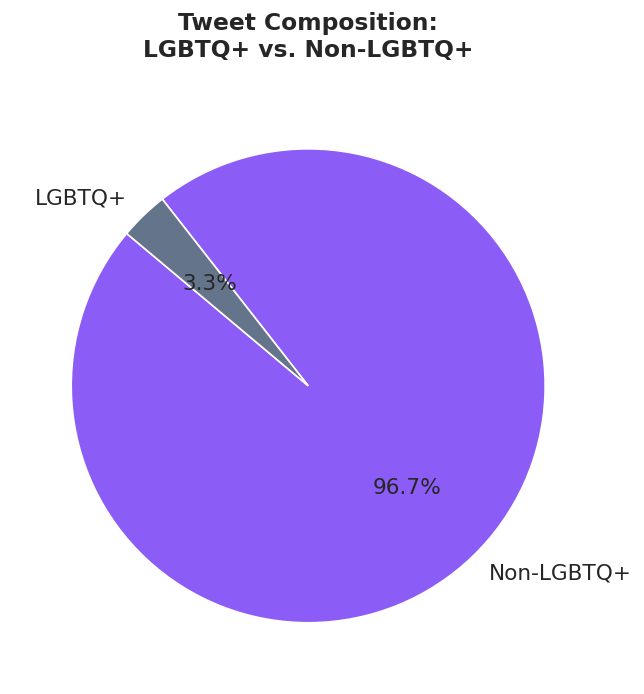

In [18]:
lgbtq_breakdown = df['lgbtq_label'].value_counts().reset_index()
lgbtq_breakdown.columns = ['Category', 'Count']
lgbtq_breakdown['Percentage'] = (lgbtq_breakdown['Count'] / total_tweets * 100).round(2)

display(lgbtq_breakdown)

# ── Pie chart ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    lgbtq_breakdown['Count'],
    labels=lgbtq_breakdown['Category'],
    colors=PALETTE,
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 13}
)
ax.set_title('Tweet Composition:\nLGBTQ+ vs. Non-LGBTQ+', pad=20)
plt.tight_layout()
plt.savefig('fig_lgbtq_pie.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.3 — Company-Level Analysis

Understanding which companies dominate by tweet volume helps contextualize whether certain firms drive overall trends.

In [19]:
# ── Tweets per company ────────────────────────────────────────────────────────
tweets_per_company = (
    df.groupby(COL['author_username'])
    .size()
    .reset_index(name='tweet_count')
    .sort_values('tweet_count', ascending=False)
)

print(f'Total companies in dataset: {len(tweets_per_company)}')
print('\nTop 10 companies by tweet volume:')
display(tweets_per_company.head(10))

Total companies in dataset: 398

Top 10 companies by tweet volume:


,author_userName,tweet_count
17,AlaskaAir,61418
382,salesforce,55747
198,McDonalds,53620
23,AmericanAir,52712
264,SouthwestAir,50169
275,Target,41831
207,MonsterEnergy,31924
112,Etsy,25216
146,Hilton,25187
10,ATT,24966


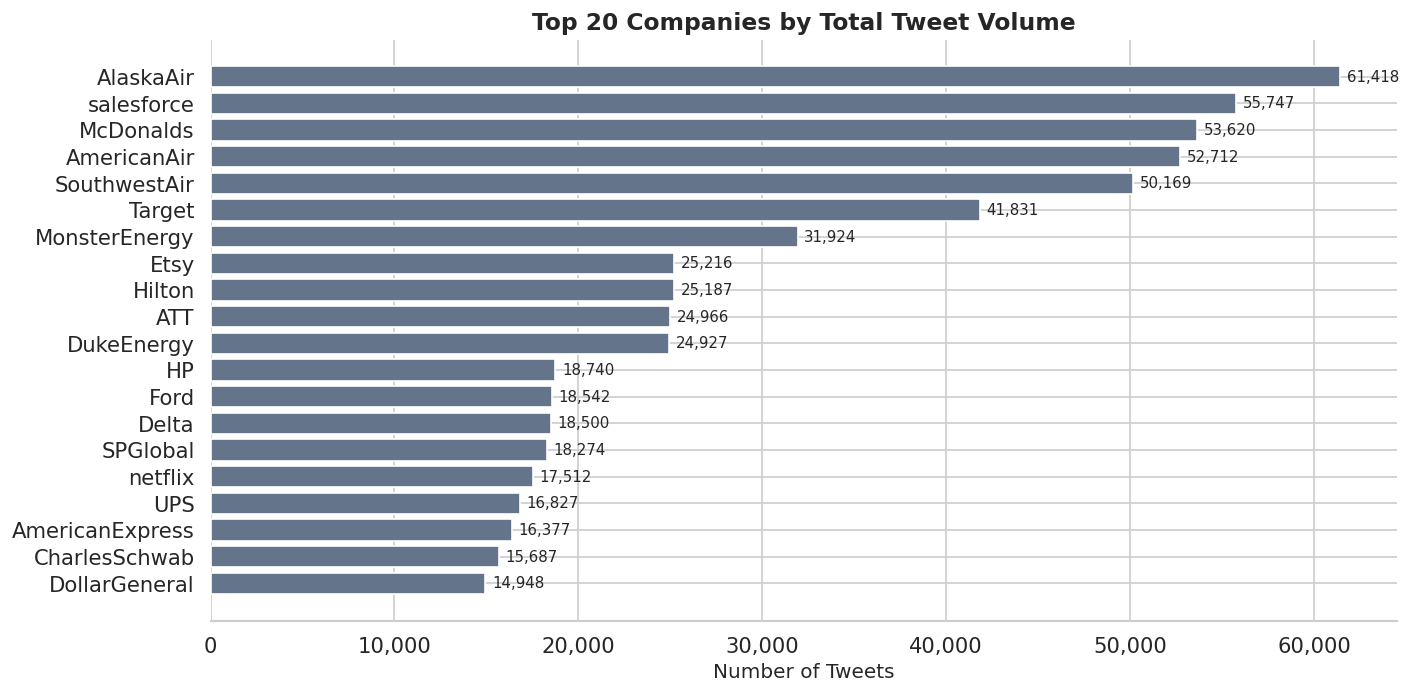

In [20]:
# ── Bar chart: Top 20 companies by total tweets ──────────────────────────────
top20 = tweets_per_company.head(20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    top20[COL['author_username']][::-1],
    top20['tweet_count'][::-1],
    color=NON_LGBTQ_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Number of Tweets')
ax.set_title('Top 20 Companies by Total Tweet Volume')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_top20_companies.png', dpi=150, bbox_inches='tight')
plt.show()

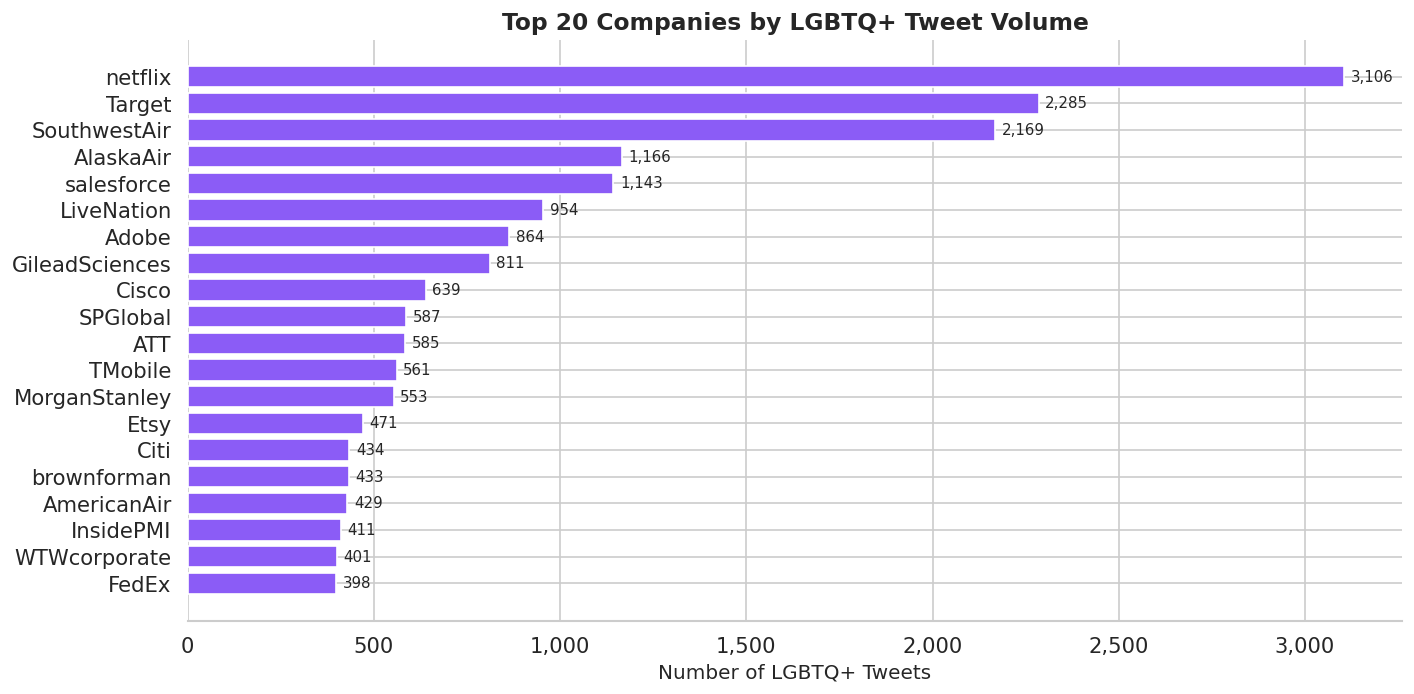

In [21]:
# ── Top 20 companies by LGBTQ+ tweet volume ──────────────────────────────────
lgbtq_per_company = (
    df[df[COL['binary']] == 1]
    .groupby(COL['author_username'])
    .size()
    .reset_index(name='lgbtq_count')
    .sort_values('lgbtq_count', ascending=False)
)

top20_lgbtq = lgbtq_per_company.head(20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    top20_lgbtq[COL['author_username']][::-1],
    top20_lgbtq['lgbtq_count'][::-1],
    color=LGBTQ_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Number of LGBTQ+ Tweets')
ax.set_title('Top 20 Companies by LGBTQ+ Tweet Volume')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_top20_lgbtq_companies.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.4 — Engagement Statistics

Engagement metrics measure how audiences respond to tweets. We compute summary statistics across all four engagement types and the composite score.

In [22]:
eng_metrics = [COL['likes'], COL['replies'], COL['retweets'], COL['quotes'], 'total_engagement']

eng_stats = df[eng_metrics].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
eng_stats.index = ['Mean', 'Median', 'Std Dev', 'Min', 'Max']

print('ENGAGEMENT SUMMARY STATISTICS')
display(eng_stats.style.format('{:,.2f}'))

ENGAGEMENT SUMMARY STATISTICS


,likeCount,replyCount,retweetCount,quoteCount,total_engagement
Mean,80.34,3.96,12.40,3.76,100.46
Median,1.00,0.00,0.00,0.00,1.00
Std Dev,"2,009.89",107.51,393.14,156.64,"2,512.20"
Min,0.00,0.00,0.00,0.00,0.00
Max,"933,066.00","48,785.00","179,639.00","64,028.00","1,128,436.00"


- Social media engagement is almost always **right-skewed**: the mean will be much higher than the median, driven by a small number of viral tweets
- If median engagement is 0 for replies/retweets, that is normal for large corporate datasets where most tweets receive no response
- High standard deviation relative to the mean confirms extreme outliers are present

## Engagement Distributions

Social media engagement is heavily skewed — most tweets get very few likes or retweets,
but a small number go viral and receive thousands. Plotting raw numbers makes the chart
unreadable, so we use a log scale to compress the range and reveal the true shape of the
distribution. The red line shows the mean (pulled up by outliers) and the blue line shows
the median (more representative of a typical tweet).

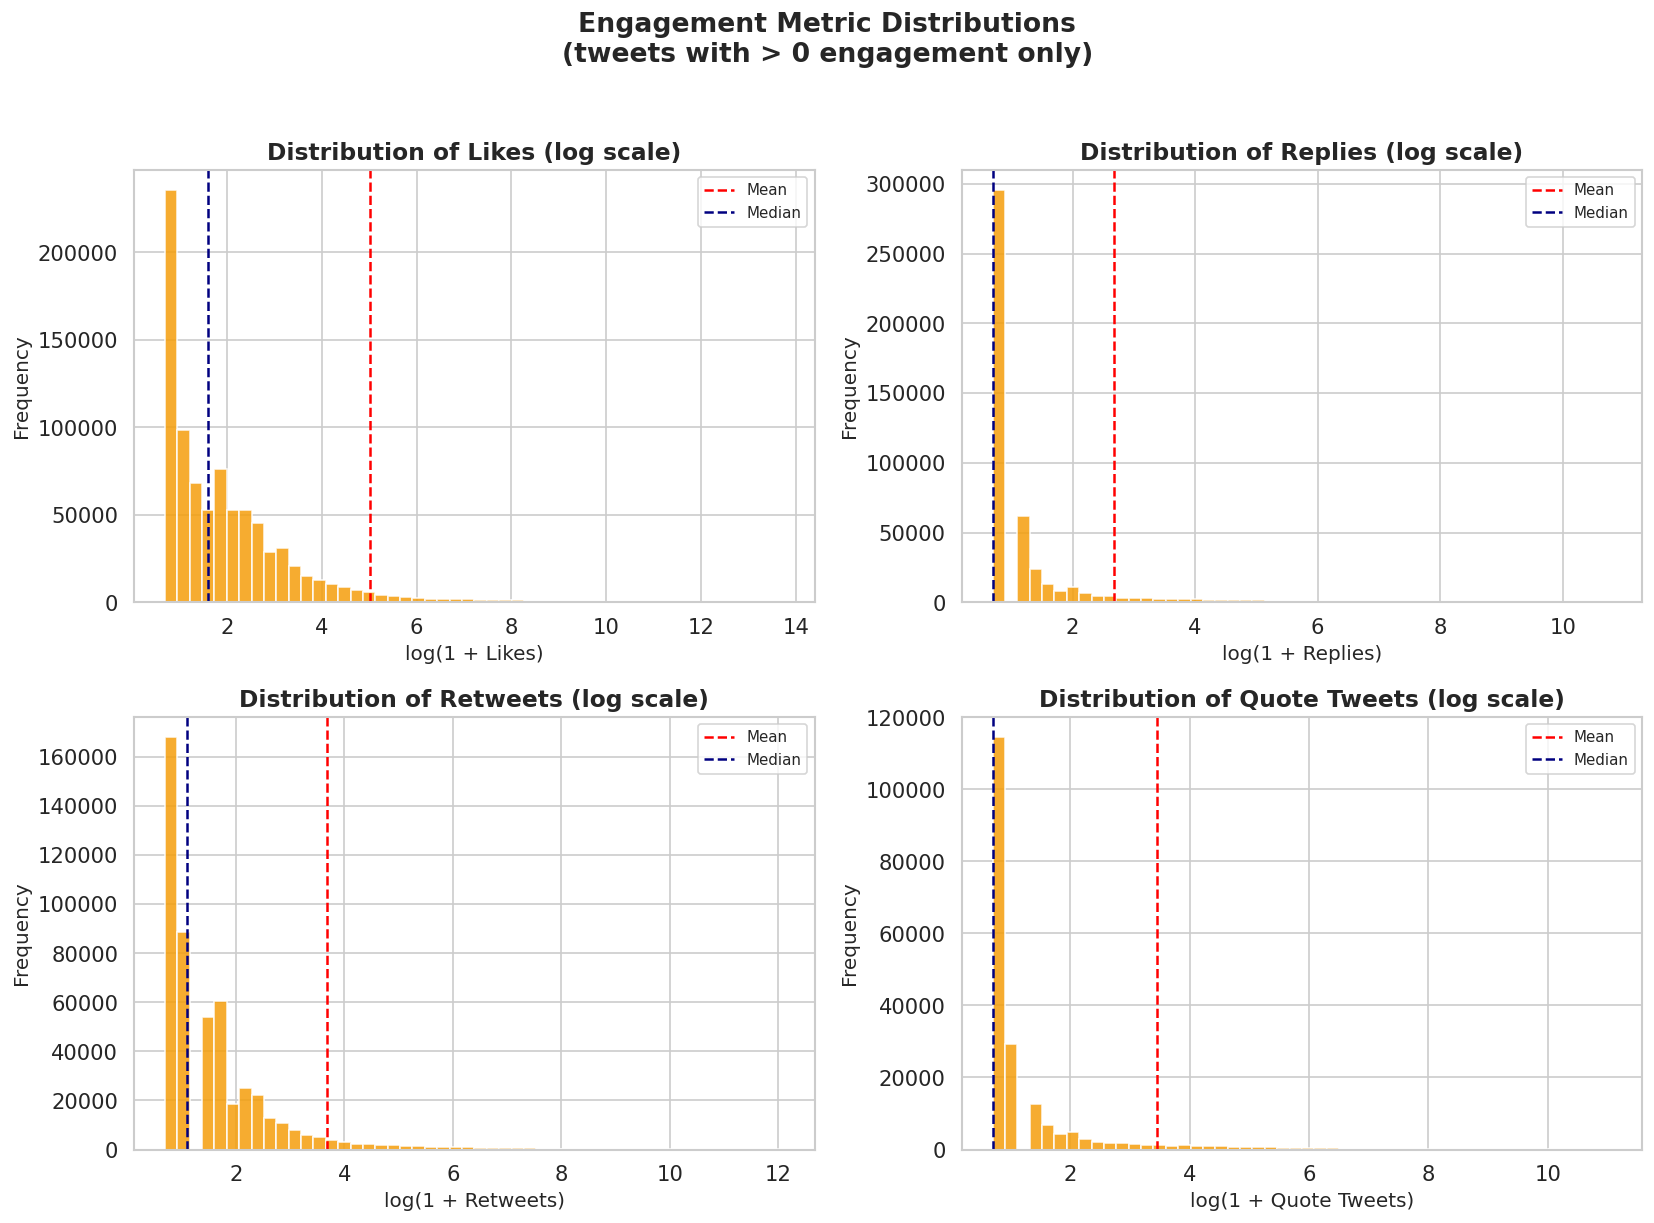

In [23]:
# ── Engagement distribution histograms (log scale) ───────────────────────────
# Log scale is used because engagement distributions are highly right-skewed

metrics_display = {
    COL['likes']    : 'Likes',
    COL['replies']  : 'Replies',
    COL['retweets'] : 'Retweets',
    COL['quotes']   : 'Quote Tweets'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (col, label) in enumerate(metrics_display.items()):
    data = df[col][df[col] > 0]   # exclude zeros for log scale
    axes[i].hist(np.log1p(data), bins=50, color=ACCENT_COLOR, edgecolor='white', alpha=0.85)
    axes[i].set_title(f'Distribution of {label} (log scale)')
    axes[i].set_xlabel(f'log(1 + {label})')
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(np.log1p(data.mean()), color='red', linestyle='--', label='Mean')
    axes[i].axvline(np.log1p(data.median()), color='navy', linestyle='--', label='Median')
    axes[i].legend(fontsize=9)

fig.suptitle('Engagement Metric Distributions\n(tweets with > 0 engagement only)', y=1.02)
plt.tight_layout()
plt.savefig('fig_engagement_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Phase 3: Trend Analysis

**Goal:** Understand how corporate social media communication, particularly LGBTQ+-related content, has changed over time from 2018 to 2023.

This phase answers:
- Is LGBTQ+ communication increasing or decreasing?
- Are there seasonal spikes (e.g., Pride Month in June)?
- How has the sentiment of corporate tweets shifted over time?

## 3.1 — Annual Tweet Volume

In [24]:
yearly = df.groupby('year').agg(
    total_tweets    = (COL['binary'], 'count'),
    lgbtq_tweets    = (COL['binary'], 'sum'),
).reset_index()

yearly['non_lgbtq_tweets'] = yearly['total_tweets'] - yearly['lgbtq_tweets']
yearly['lgbtq_pct']        = (yearly['lgbtq_tweets'] / yearly['total_tweets'] * 100).round(2)

print('ANNUAL TWEET VOLUMES')
display(yearly)

ANNUAL TWEET VOLUMES


,year,total_tweets,lgbtq_tweets,non_lgbtq_tweets,lgbtq_pct
0,2018,201924,6162,195762,3.05
1,2019,201834,7283,194551,3.61
2,2020,195826,7437,188389,3.80
3,2021,234212,9578,224634,4.09
4,2022,271079,9386,261693,3.46
5,2023,301305,8990,292315,2.98
6,2024,179320,3955,175365,2.21


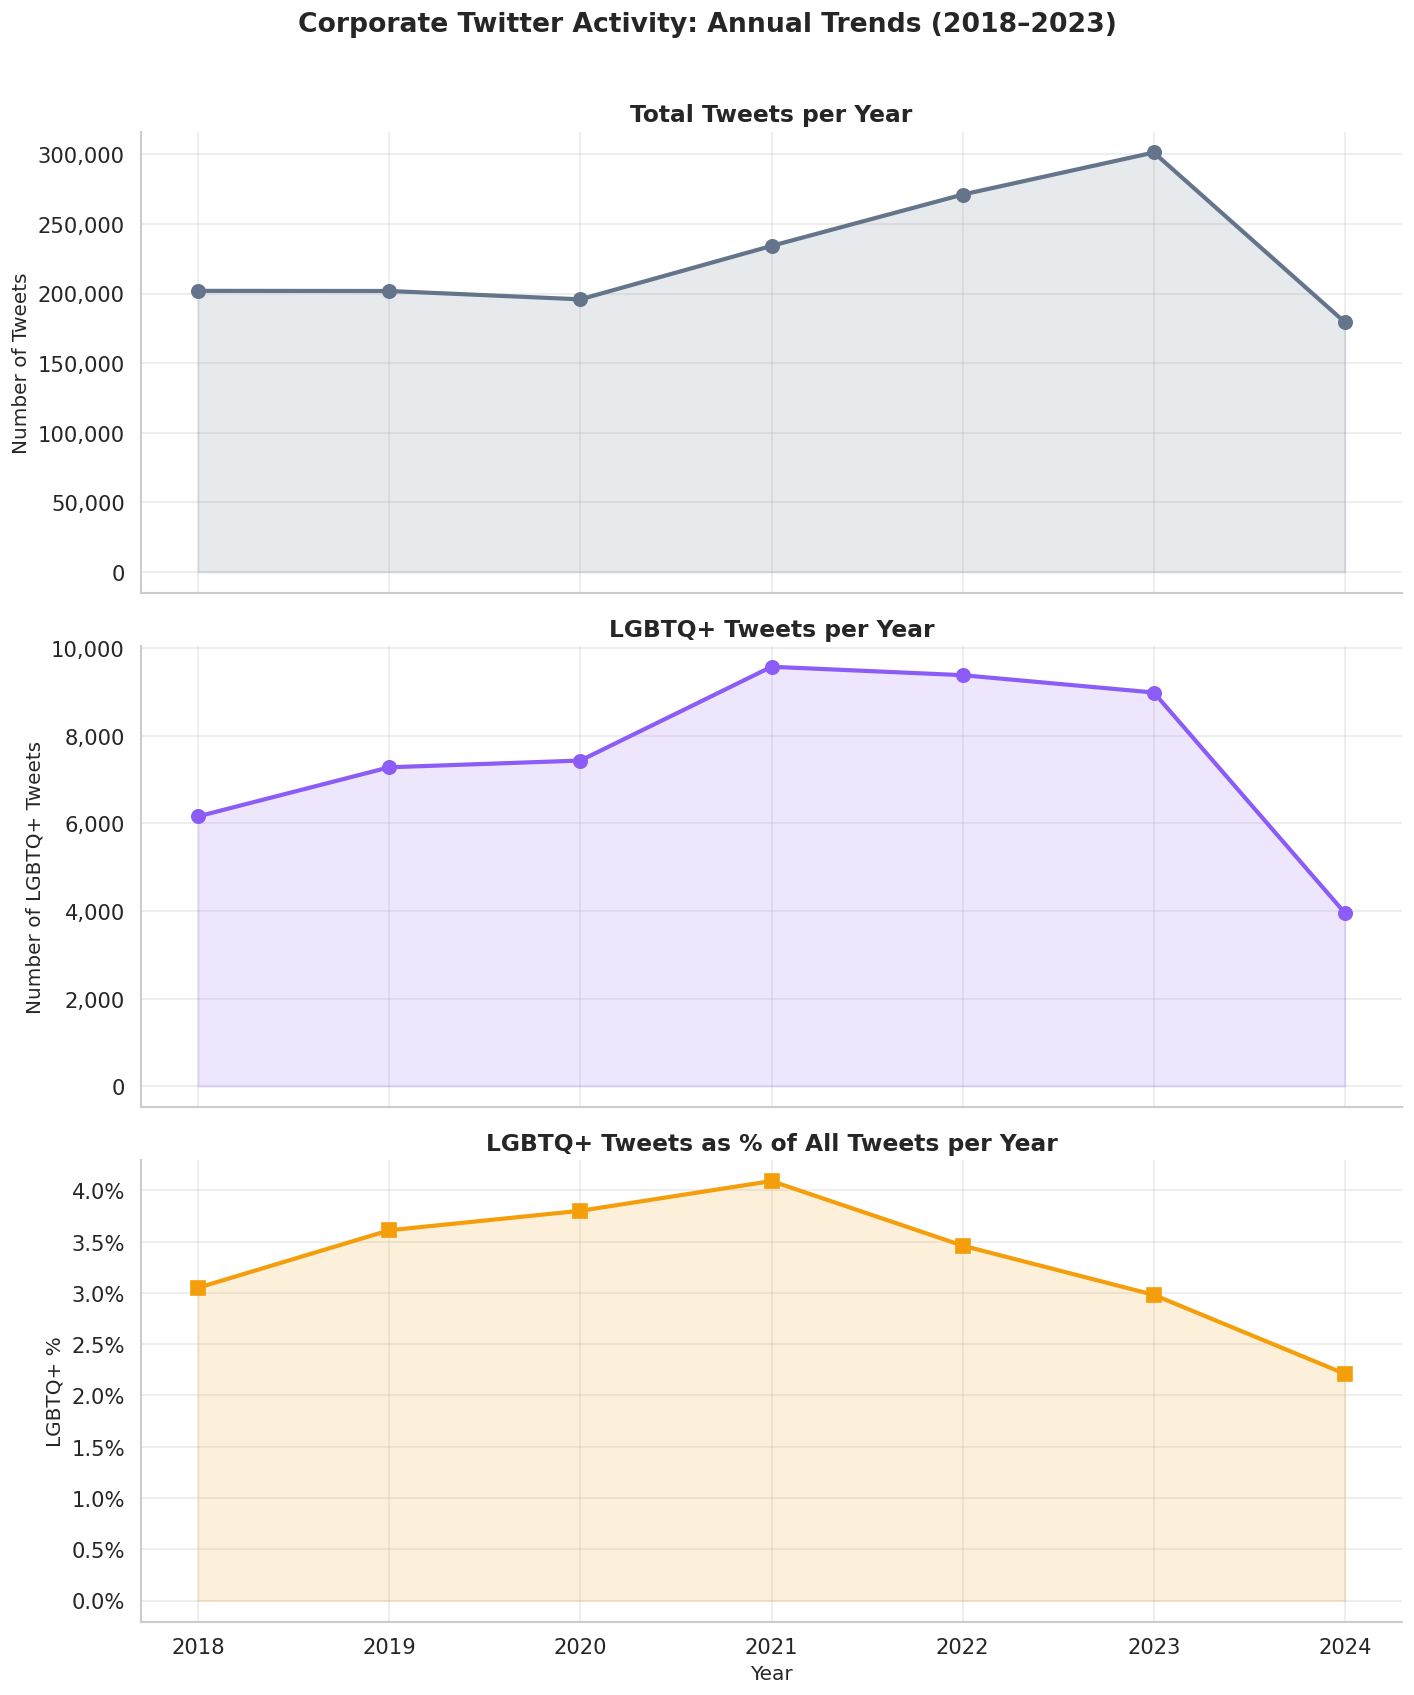

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14), sharex=True)

# ── Panel 1: Total tweets per year ───────────────────────────────────────────
axes[0].plot(yearly['year'], yearly['total_tweets'],
             marker='o', linewidth=2.5, color=NON_LGBTQ_COLOR, markersize=8)
axes[0].fill_between(yearly['year'], yearly['total_tweets'],
                      alpha=0.15, color=NON_LGBTQ_COLOR)
axes[0].set_title('Total Tweets per Year')
axes[0].set_ylabel('Number of Tweets')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# ── Panel 2: LGBTQ+ tweets per year ─────────────────────────────────────────
axes[1].plot(yearly['year'], yearly['lgbtq_tweets'],
             marker='o', linewidth=2.5, color=LGBTQ_COLOR, markersize=8)
axes[1].fill_between(yearly['year'], yearly['lgbtq_tweets'],
                      alpha=0.15, color=LGBTQ_COLOR)
axes[1].set_title('LGBTQ+ Tweets per Year')
axes[1].set_ylabel('Number of LGBTQ+ Tweets')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# ── Panel 3: % LGBTQ+ by year ────────────────────────────────────────────────
axes[2].plot(yearly['year'], yearly['lgbtq_pct'],
             marker='s', linewidth=2.5, color=ACCENT_COLOR, markersize=8)
axes[2].fill_between(yearly['year'], yearly['lgbtq_pct'],
                      alpha=0.15, color=ACCENT_COLOR)
axes[2].set_title('LGBTQ+ Tweets as % of All Tweets per Year')
axes[2].set_ylabel('LGBTQ+ %')
axes[2].set_xlabel('Year')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
axes[2].set_xticks(yearly['year'])

for ax in axes:
    ax.grid(True, alpha=0.4)
    sns.despine(ax=ax)

fig.suptitle('Corporate Twitter Activity: Annual Trends (2018–2023)', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('fig_annual_trends.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.2 — Monthly Tweet Volume (Seasonality & Pride Month)

June is **Pride Month**, and we expect to see elevated LGBTQ+ corporate communication in that month each year.

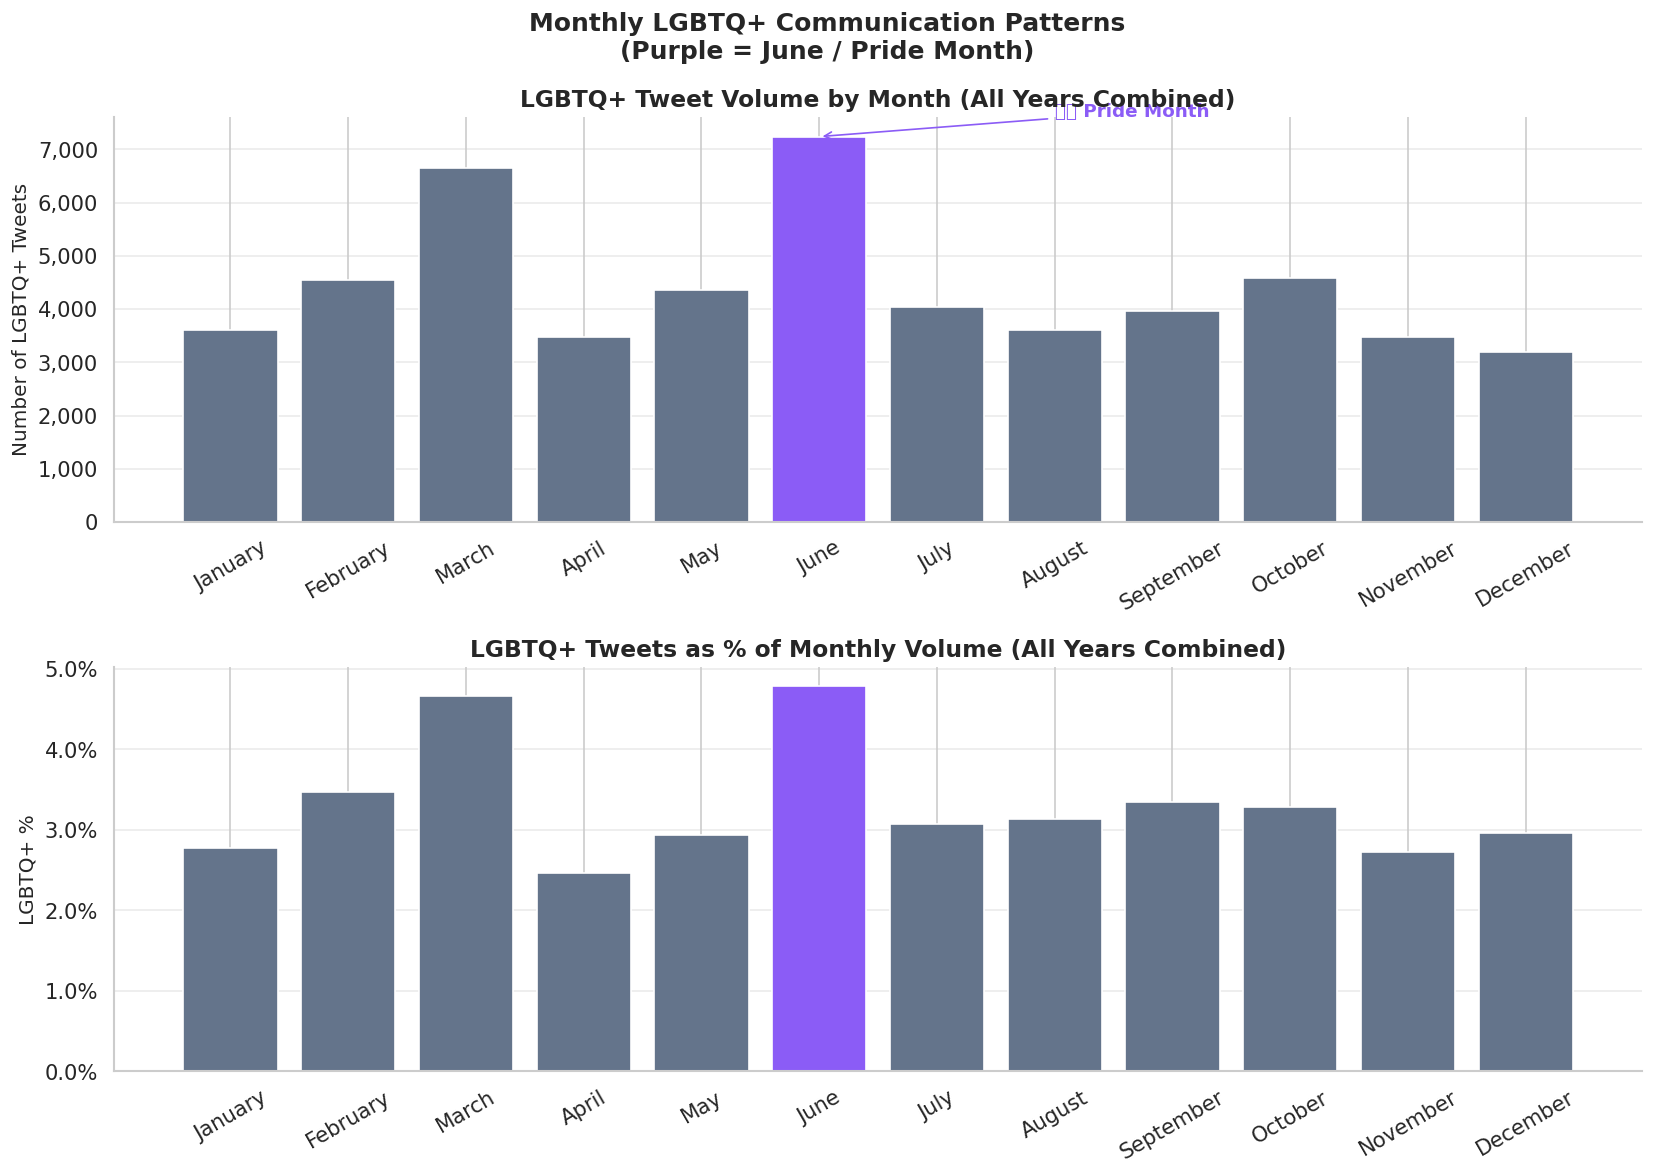

In [26]:
monthly = df.groupby('month_name', observed=True).agg(
    total_tweets = (COL['binary'], 'count'),
    lgbtq_tweets = (COL['binary'], 'sum'),
).reset_index()

monthly['lgbtq_pct'] = (monthly['lgbtq_tweets'] / monthly['total_tweets'] * 100).round(2)

# Color: highlight June (Pride Month) in a distinct color
bar_colors = [LGBTQ_COLOR if m == 'June' else NON_LGBTQ_COLOR for m in monthly['month_name']]

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# ── Panel 1: LGBTQ+ tweets per month ─────────────────────────────────────────
axes[0].bar(monthly['month_name'], monthly['lgbtq_tweets'], color=bar_colors, edgecolor='white')
axes[0].set_title('LGBTQ+ Tweet Volume by Month (All Years Combined)')
axes[0].set_ylabel('Number of LGBTQ+ Tweets')
axes[0].tick_params(axis='x', rotation=30)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Add Pride Month annotation
june_val = monthly.loc[monthly['month_name'] == 'June', 'lgbtq_tweets'].values
if len(june_val) > 0:
    axes[0].annotate(
        '🏳️‍🌈 Pride Month',
        xy=('June', june_val[0]),
        xytext=('August', june_val[0] * 1.05),
        fontsize=11, color=LGBTQ_COLOR, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=LGBTQ_COLOR)
    )

# ── Panel 2: % LGBTQ+ per month ──────────────────────────────────────────────
axes[1].bar(monthly['month_name'], monthly['lgbtq_pct'], color=bar_colors, edgecolor='white')
axes[1].set_title('LGBTQ+ Tweets as % of Monthly Volume (All Years Combined)')
axes[1].set_ylabel('LGBTQ+ %')
axes[1].tick_params(axis='x', rotation=30)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))

for ax in axes:
    sns.despine(ax=ax)
    ax.grid(axis='y', alpha=0.4)

fig.suptitle('Monthly LGBTQ+ Communication Patterns\n(Purple = June / Pride Month)', fontsize=15)
plt.tight_layout()
plt.savefig('fig_monthly_lgbtq.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.3 — Pride Month Trend by Year

We isolate June across years to see if corporate Pride Month participation has grown, stabilized, or declined.

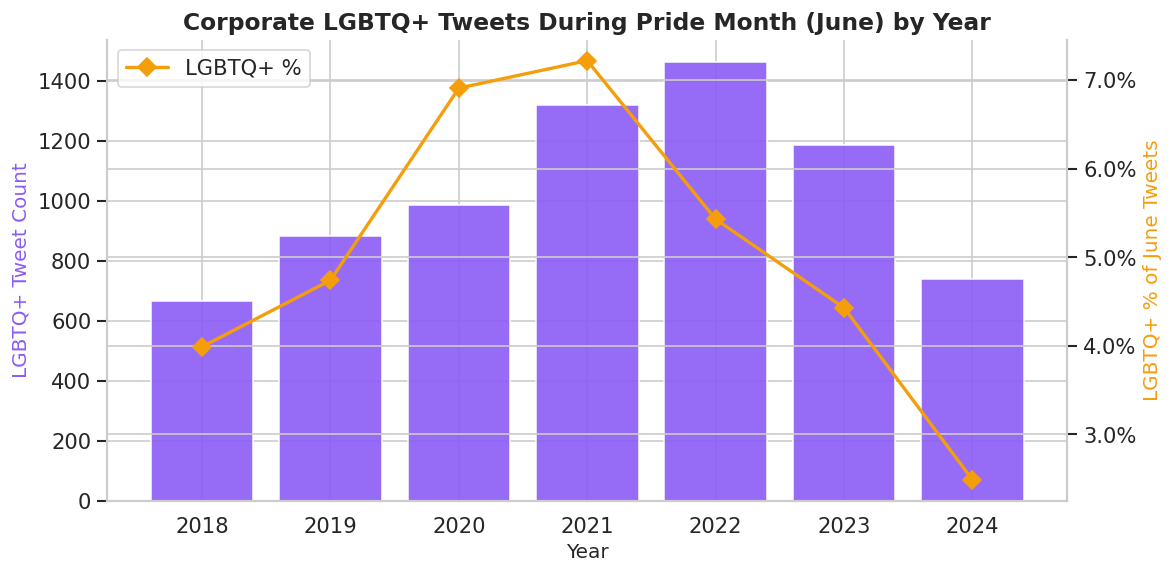

In [27]:
pride_monthly = (
    df[df['month'] == 6]
    .groupby('year')
    .agg(
        total_june   = (COL['binary'], 'count'),
        lgbtq_june   = (COL['binary'], 'sum'),
    )
    .reset_index()
)
pride_monthly['lgbtq_pct_june'] = (
    pride_monthly['lgbtq_june'] / pride_monthly['total_june'] * 100
).round(2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pride_monthly['year'], pride_monthly['lgbtq_june'], color=LGBTQ_COLOR, edgecolor='white', alpha=0.9)
ax2 = ax.twinx()
ax2.plot(pride_monthly['year'], pride_monthly['lgbtq_pct_june'],
         color=ACCENT_COLOR, marker='D', linewidth=2, markersize=8, label='LGBTQ+ %')
ax.set_title('Corporate LGBTQ+ Tweets During Pride Month (June) by Year')
ax.set_xlabel('Year')
ax.set_ylabel('LGBTQ+ Tweet Count', color=LGBTQ_COLOR)
ax2.set_ylabel('LGBTQ+ % of June Tweets', color=ACCENT_COLOR)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
ax.set_xticks(pride_monthly['year'])
ax2.legend(loc='upper left')
sns.despine(right=False)
plt.tight_layout()
plt.savefig('fig_pride_month_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.4 — Sentiment Trends Over Time

We examine how the average sentiment of corporate tweets has shifted by year and month.

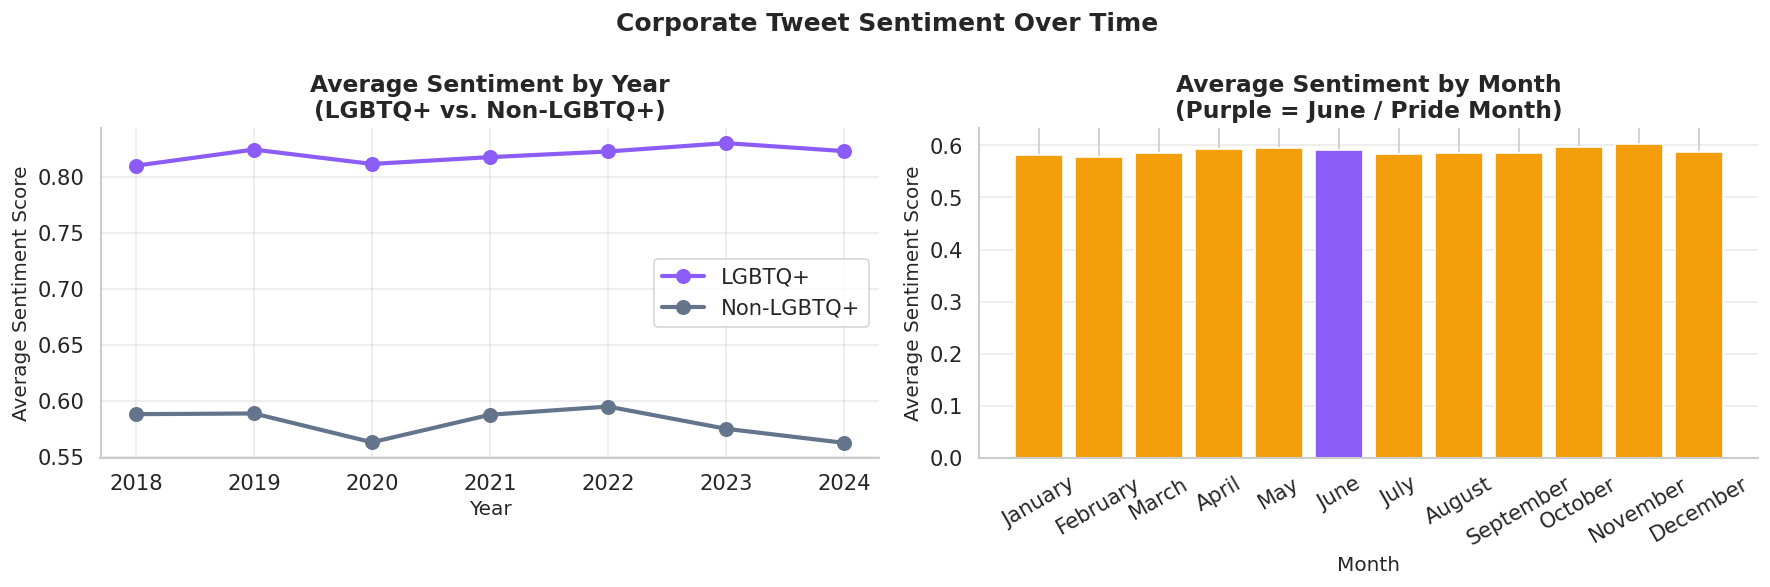

In [28]:
sent_col = COL['sentiment']

# ── Average sentiment by year ────────────────────────────────────────────────
sent_by_year = df.groupby('year')[sent_col].mean().reset_index()
sent_by_year.columns = ['year', 'avg_sentiment']

# ── Average sentiment by month ───────────────────────────────────────────────
sent_by_month = df.groupby('month_name', observed=True)[sent_col].mean().reset_index()
sent_by_month.columns = ['month_name', 'avg_sentiment']

# ── Average sentiment by year AND LGBTQ+ label ───────────────────────────────
sent_by_year_lgbtq = df.groupby(['year', 'lgbtq_label'])[sent_col].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Sentiment by year (split by LGBTQ+ category)
for label, color in zip(['LGBTQ+', 'Non-LGBTQ+'], PALETTE):
    subset = sent_by_year_lgbtq[sent_by_year_lgbtq['lgbtq_label'] == label]
    axes[0].plot(subset['year'], subset[sent_col],
                 marker='o', linewidth=2.5, color=color, label=label, markersize=8)
axes[0].set_title('Average Sentiment by Year\n(LGBTQ+ vs. Non-LGBTQ+)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Average Sentiment Score')
axes[0].legend()
axes[0].set_xticks(sent_by_year_lgbtq['year'].unique())
axes[0].grid(True, alpha=0.4)
sns.despine(ax=axes[0])

# Panel 2: Sentiment by month
month_colors = [LGBTQ_COLOR if m == 'June' else ACCENT_COLOR for m in sent_by_month['month_name']]
axes[1].bar(sent_by_month['month_name'], sent_by_month['avg_sentiment'],
            color=month_colors, edgecolor='white')
axes[1].set_title('Average Sentiment by Month\n(Purple = June / Pride Month)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Sentiment Score')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', alpha=0.4)
sns.despine(ax=axes[1])

fig.suptitle('Corporate Tweet Sentiment Over Time', fontsize=15)
plt.tight_layout()
plt.savefig('fig_sentiment_trends.png', dpi=150, bbox_inches='tight')
plt.show()

**✅ Phase 3 Complete.** We now have a full picture of how corporate LGBTQ+ communication and sentiment has evolved year over year and month over month.

---
# Phase 4: Engagement Analysis

**Goal:** Understand how audiences respond to corporate tweets, and whether LGBTQ+ content drives different engagement than general content.



## 4.1 — LGBTQ+ vs. Non-LGBTQ+ Engagement Comparison

We compare mean engagement across all five metrics. The boxplot and violin plot show the full distribution, not just the average.

In [29]:
# ── Mean engagement by LGBTQ+ label ──────────────────────────────────────────
eng_compare = df.groupby('lgbtq_label')[
    [COL['likes'], COL['replies'], COL['retweets'], COL['quotes'], 'total_engagement']
].mean().round(2)

print('MEAN ENGAGEMENT: LGBTQ+ vs. NON-LGBTQ+ TWEETS')
display(eng_compare.style.format('{:,.2f}').background_gradient(cmap='Purples', axis=0))

MEAN ENGAGEMENT: LGBTQ+ vs. NON-LGBTQ+ TWEETS


,likeCount,replyCount,retweetCount,quoteCount,total_engagement
lgbtq_label,,,,,
LGBTQ+,358.05,11.48,56.14,23.21,448.89
Non-LGBTQ+,70.78,3.70,10.90,3.08,88.46


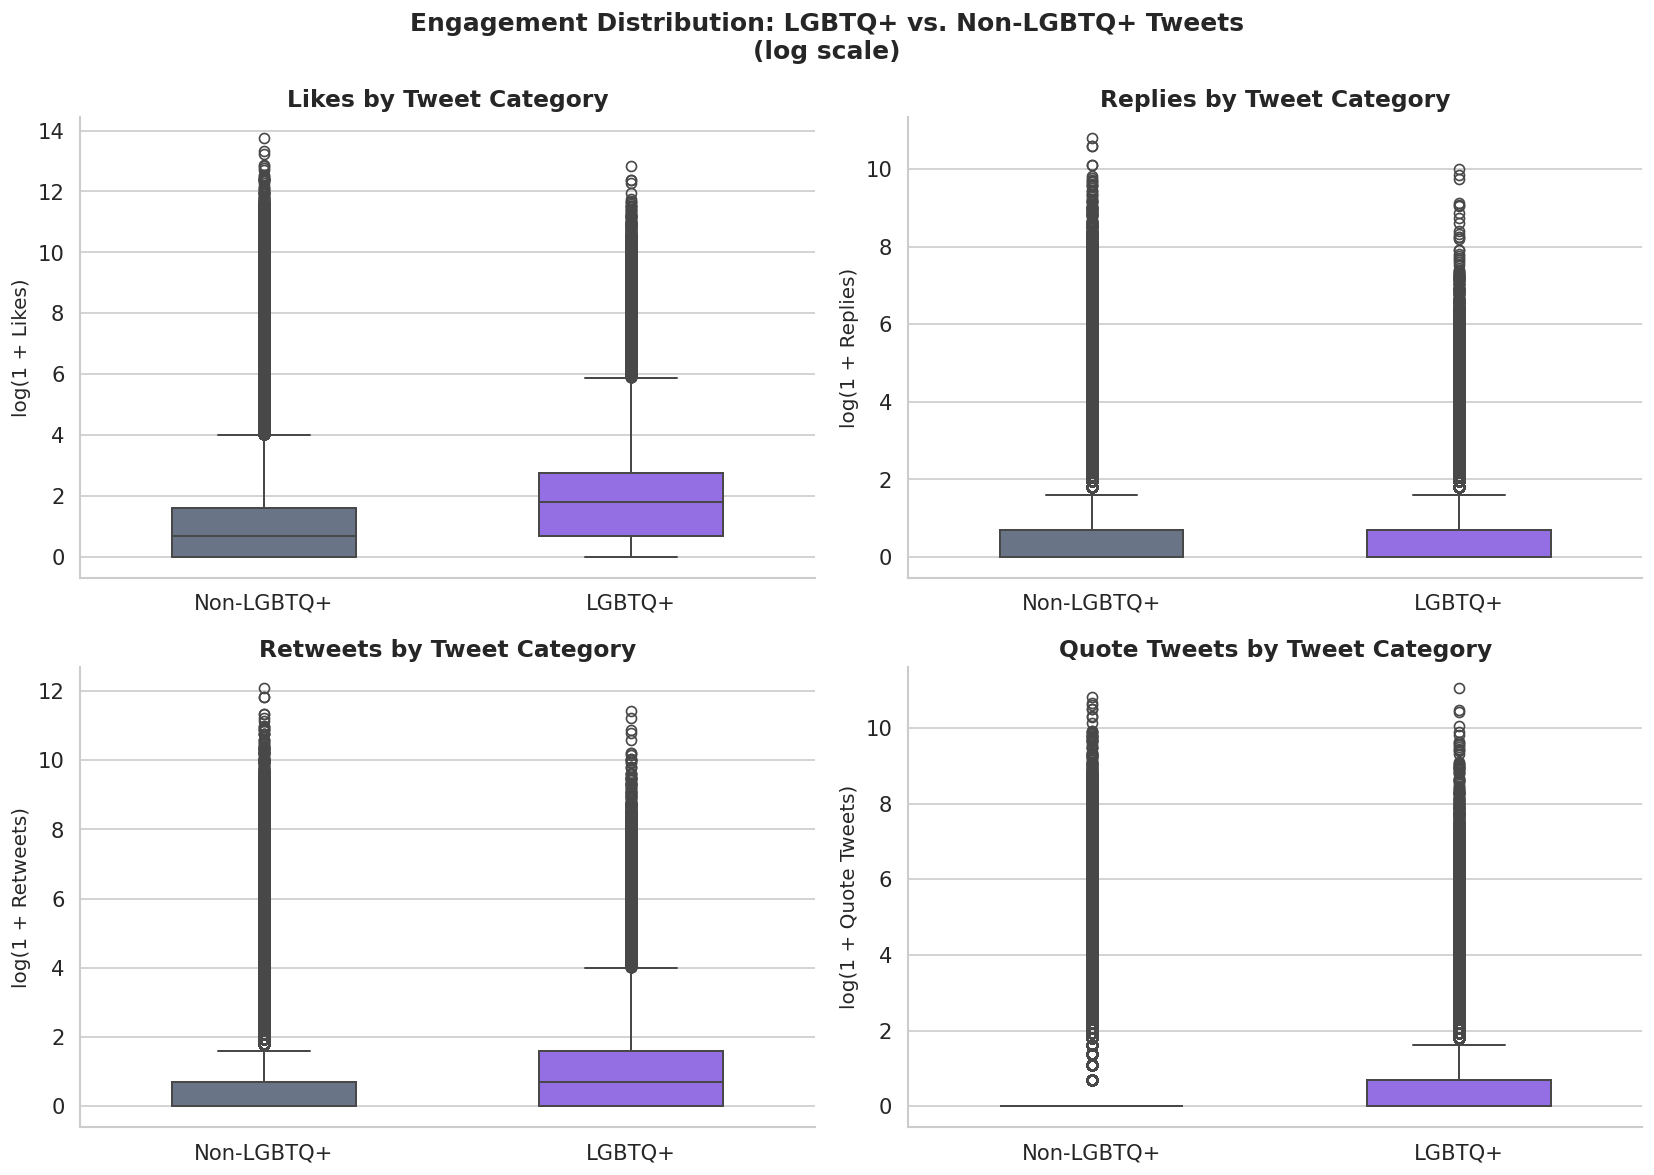

In [30]:
# ── Boxplots: engagement by LGBTQ+ label ─────────────────────────────────────
# Use log1p transform because raw distributions are extremely right-skewed

metrics_to_plot = {
    COL['likes']    : 'Likes',
    COL['replies']  : 'Replies',
    COL['retweets'] : 'Retweets',
    COL['quotes']   : 'Quote Tweets'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (col, label) in enumerate(metrics_to_plot.items()):
    plot_data = df.copy()
    plot_data[col] = np.log1p(plot_data[col])

    sns.boxplot(
        data=plot_data,
        x='lgbtq_label', y=col,
        palette={'LGBTQ+': LGBTQ_COLOR, 'Non-LGBTQ+': NON_LGBTQ_COLOR},
        width=0.5, linewidth=1.2,
        ax=axes[i]
    )
    axes[i].set_title(f'{label} by Tweet Category')
    axes[i].set_xlabel('')
    axes[i].set_ylabel(f'log(1 + {label})')
    sns.despine(ax=axes[i])

fig.suptitle('Engagement Distribution: LGBTQ+ vs. Non-LGBTQ+ Tweets\n(log scale)', fontsize=15)
plt.tight_layout()
plt.savefig('fig_boxplots_engagement.png', dpi=150, bbox_inches='tight')
plt.show()

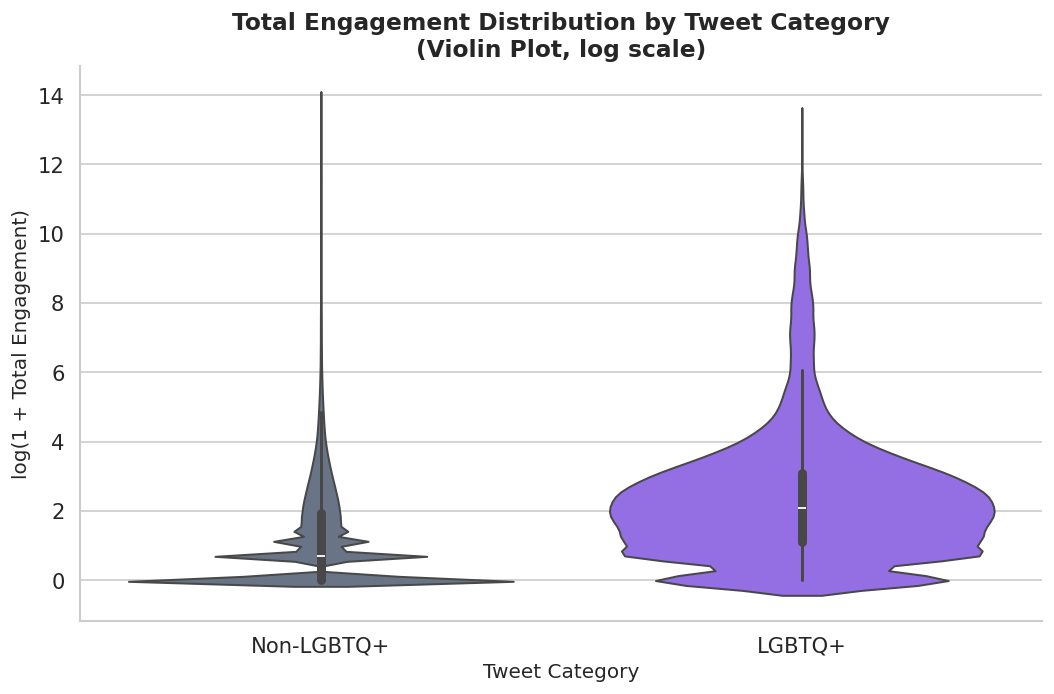

In [31]:
# ── Violin plots: total engagement by LGBTQ+ label ───────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = df.copy()
plot_data['total_engagement_log'] = np.log1p(plot_data['total_engagement'])

sns.violinplot(
    data=plot_data,
    x='lgbtq_label', y='total_engagement_log',
    palette={'LGBTQ+': LGBTQ_COLOR, 'Non-LGBTQ+': NON_LGBTQ_COLOR},
    inner='box', linewidth=1.2,
    ax=ax
)
ax.set_title('Total Engagement Distribution by Tweet Category\n(Violin Plot, log scale)')
ax.set_xlabel('Tweet Category')
ax.set_ylabel('log(1 + Total Engagement)')
sns.despine()
plt.tight_layout()
plt.savefig('fig_violin_total_engagement.png', dpi=150, bbox_inches='tight')
plt.show()



LGBTQ+ tweets consistently show higher engagement than non-LGBTQ+ tweets across all four metrics. The boxplots show that the median LGBTQ+ tweet outperforms the median non-LGBTQ+ tweet in likes, replies, retweets, and quote tweets. The violin plot reinforces this — the non-LGBTQ+ distribution is heavily concentrated near zero, while LGBTQ+ tweets show a much wider spread of engagement, suggesting audiences respond more actively to LGBTQ+-related corporate content.

## 4.2 — Average Engagement by Company (Top 20)

We identify which companies achieve the highest average engagement per tweet, overall and specifically for LGBTQ+ content.

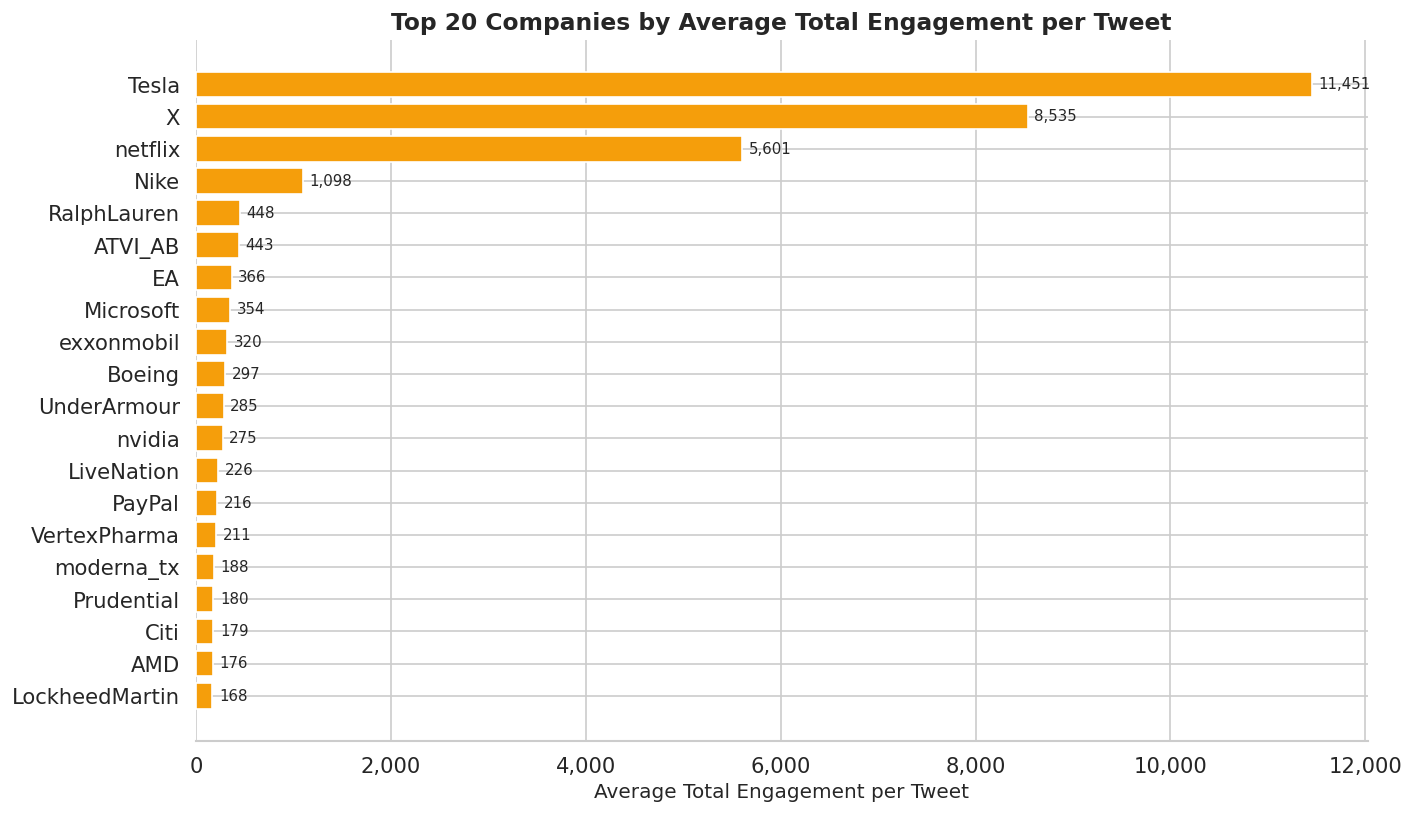

In [32]:
# ── Average total engagement per tweet by company ─────────────────────────────
company_eng = (
    df.groupby(COL['author_username'])
    .agg(
        avg_total_engagement = ('total_engagement', 'mean'),
        tweet_count          = (COL['binary'], 'count')
    )
    .reset_index()
    .sort_values('avg_total_engagement', ascending=False)
)

top20_eng = company_eng.head(20)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    top20_eng[COL['author_username']][::-1],
    top20_eng['avg_total_engagement'][::-1],
    color=ACCENT_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Average Total Engagement per Tweet')
ax.set_title('Top 20 Companies by Average Total Engagement per Tweet')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_company_avg_engagement.png', dpi=150, bbox_inches='tight')
plt.show()

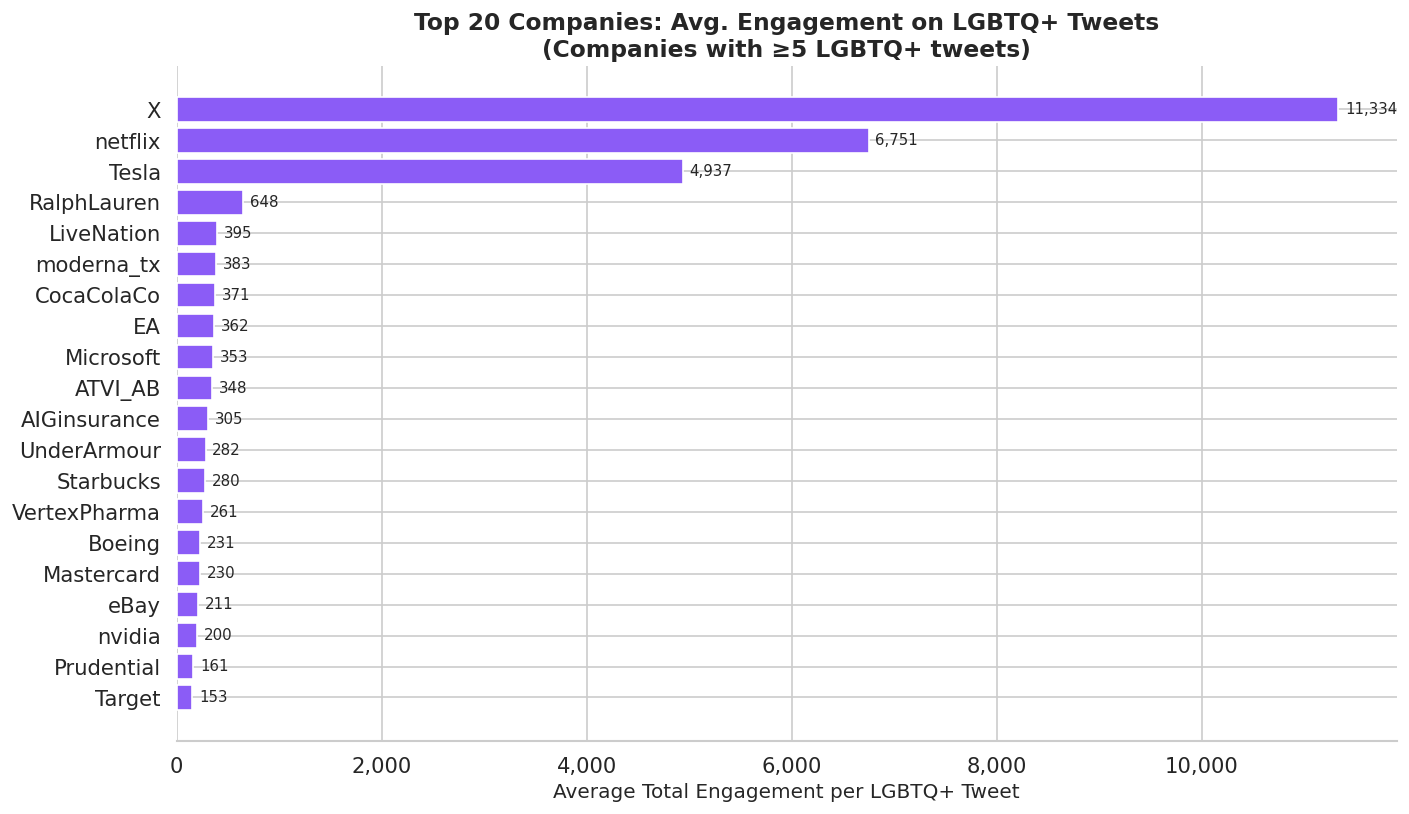

In [33]:
# ── Average engagement on LGBTQ+ tweets by company ───────────────────────────
lgbtq_eng = (
    df[df[COL['binary']] == 1]
    .groupby(COL['author_username'])
    .agg(
        avg_lgbtq_engagement = ('total_engagement', 'mean'),
        lgbtq_tweet_count    = (COL['binary'], 'count')
    )
    .reset_index()
    .query('lgbtq_tweet_count >= 5')    # only include companies with ≥5 LGBTQ+ tweets
    .sort_values('avg_lgbtq_engagement', ascending=False)
)

top20_lgbtq_eng = lgbtq_eng.head(20)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    top20_lgbtq_eng[COL['author_username']][::-1],
    top20_lgbtq_eng['avg_lgbtq_engagement'][::-1],
    color=LGBTQ_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Average Total Engagement per LGBTQ+ Tweet')
ax.set_title('Top 20 Companies: Avg. Engagement on LGBTQ+ Tweets\n(Companies with ≥5 LGBTQ+ tweets)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_company_lgbtq_engagement.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.3 — Top LGBTQ+ Tweets by Engagement

Examining the highest-engagement LGBTQ+ tweets reveals what content formats, tones, or topics resonated most strongly with audiences.

In [34]:
top_lgbtq_tweets = (
    df[df[COL['binary']] == 1]
    [[COL['author_username'], COL['text'], COL['likes'], COL['retweets'],
      COL['replies'], 'total_engagement', COL['sentiment'], 'year']]
    .sort_values('total_engagement', ascending=False)
    .head(15)
    .reset_index(drop=True)
)

top_lgbtq_tweets.index += 1   # start rank from 1

print('TOP 15 LGBTQ+ TWEETS BY TOTAL ENGAGEMENT')
display(top_lgbtq_tweets.style
    .background_gradient(subset=['total_engagement'], cmap='Purples')
    .format({
        COL['likes']    : '{:,.0f}',
        COL['retweets'] : '{:,.0f}',
        COL['replies']  : '{:,.0f}',
        'total_engagement' : '{:,.0f}',
        COL['sentiment']: '{:.3f}'
    }))

---
# Extension: Original Posts Analysis (Replies Excluded)

**Why this matters:** A significant portion of corporate tweets are *replies* — reactive customer-service messages directed at individual users. Accounts like airlines and telecoms can generate tens of thousands of replies, which inflates their raw tweet counts and makes them appear far more "active" than companies that focus on broadcast communication.

Filtering to **original posts only** gives a cleaner measure of deliberate corporate communication strategy: the content a company actively chose to put in front of its full audience, rather than responses triggered by inbound complaints or questions.

The analyses below mirror the company-level analyses in Phase 2 but use only original (non-reply) tweets.

In [35]:
# ── Detect the reply indicator column automatically ──────────────────────────
# Checks COL map first, then falls back to scanning column names directly.
reply_col = COL.get('is_reply')

if reply_col not in df.columns:
    # Fallback: search for any column whose name contains 'reply' (case-insensitive)
    candidates = [c for c in df.columns if 'reply' in c.lower() and df[c].dtype == bool]
    reply_col = candidates[0] if candidates else None

if reply_col is None:
    raise ValueError('❌ Could not detect a reply indicator column. '
                     'Update COL["is_reply"] in the Column Name Mapping cell.')

print(f'✅ Reply indicator column detected: "{reply_col}"')
print(f'   Total tweets          : {len(df):>10,}')
print(f'   Replies               : {df[reply_col].sum():>10,}  ({df[reply_col].mean()*100:.1f}%)')
print(f'   Original posts        : {(~df[reply_col]).sum():>10,}  ({(~df[reply_col]).mean()*100:.1f}%)')

# ── Create filtered dataframe of original posts only ────────────────────────
df_orig = df[~df[reply_col]].copy()
print(f'\n✅ df_orig created: {len(df_orig):,} original (non-reply) tweets.')

✅ Reply indicator column detected: "isReply"
   Total tweets          :  1,585,500
   Replies               :    858,550  (54.2%)
   Original posts        :    726,950  (45.8%)

✅ df_orig created: 726,950 original (non-reply) tweets.


## 5.1 — Top Companies by Total Original Posts

Companies with at least 1 original post: 397

Top 10 companies by original post volume:


,author_userName,original_post_count
255,SPGlobal,16851
88,DXCTechnology,12340
382,salesforce,11432
368,netflix,10806
115,F5,9517
234,Paycom,8888
203,MicrochipTech,8805
185,LiveNation,8375
109,Equinix,8263
206,MolsonCoors,7440


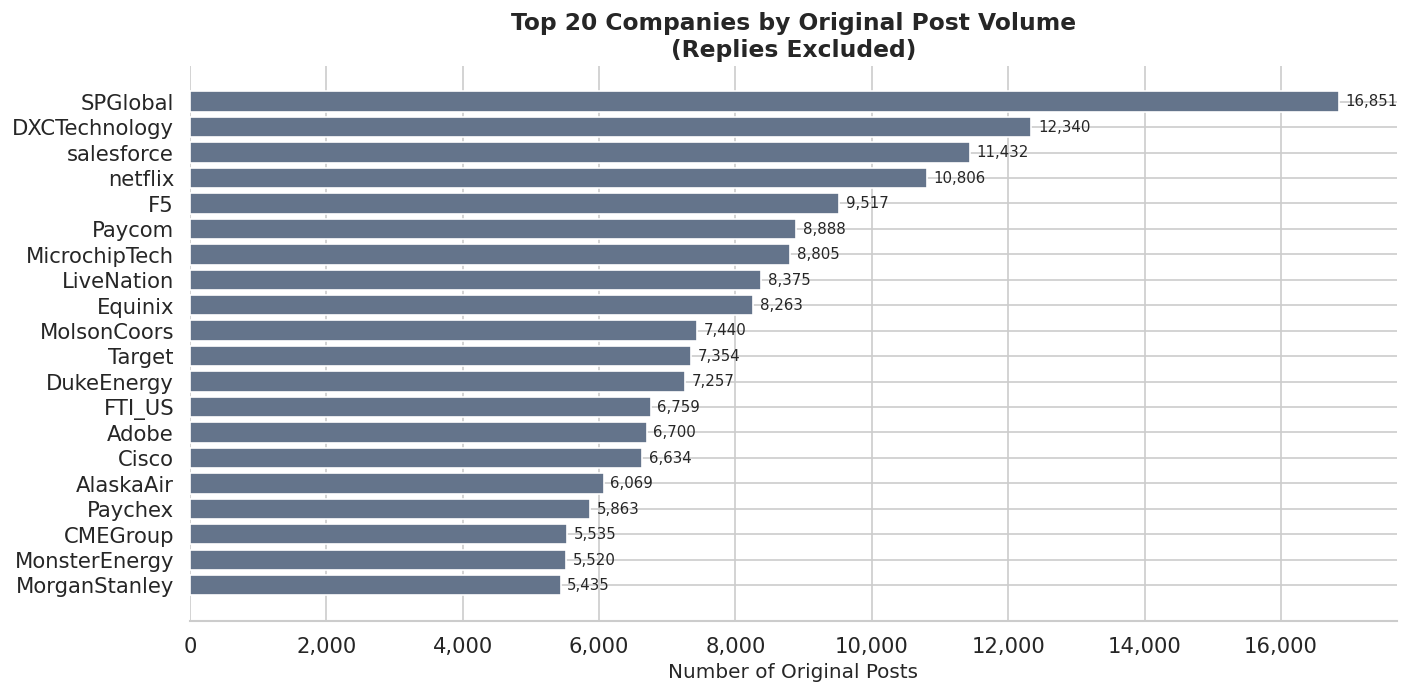

In [36]:
# ── Tweets per company (original posts only) ─────────────────────────────────
orig_per_company = (
    df_orig.groupby(COL['author_username'])
    .size()
    .reset_index(name='original_post_count')
    .sort_values('original_post_count', ascending=False)
)

print(f'Companies with at least 1 original post: {len(orig_per_company):,}')
print('\nTop 10 companies by original post volume:')
display(orig_per_company.head(10))

# ── Bar chart ────────────────────────────────────────────────────────────────
top20_orig = orig_per_company.head(20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    top20_orig[COL['author_username']][::-1],
    top20_orig['original_post_count'][::-1],
    color=NON_LGBTQ_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Number of Original Posts')
ax.set_title('Top 20 Companies by Original Post Volume\n(Replies Excluded)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_top20_orig_posts.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.2 — Top Companies by LGBTQ+ Original Posts

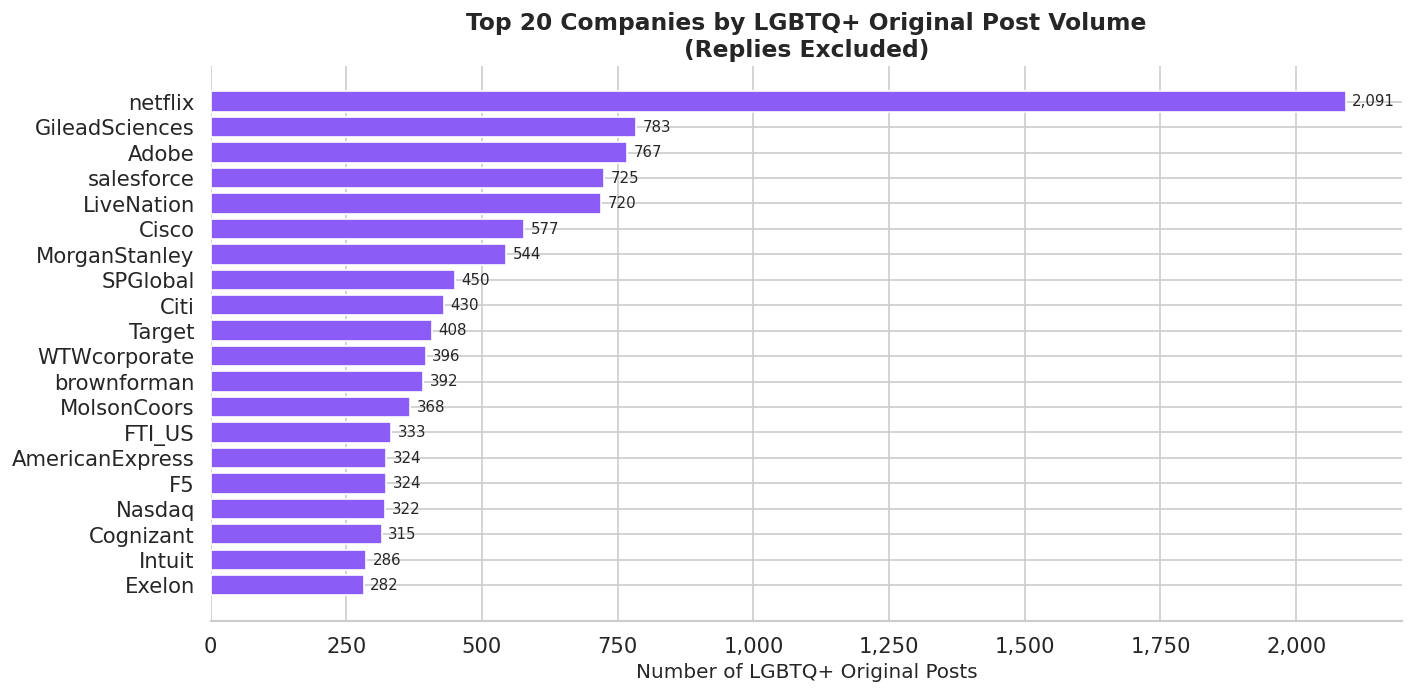

In [37]:
# ── LGBTQ+ original posts per company ────────────────────────────────────────
orig_lgbtq_per_company = (
    df_orig[df_orig[COL['binary']] == 1]
    .groupby(COL['author_username'])
    .size()
    .reset_index(name='lgbtq_orig_count')
    .sort_values('lgbtq_orig_count', ascending=False)
)

top20_orig_lgbtq = orig_lgbtq_per_company.head(20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    top20_orig_lgbtq[COL['author_username']][::-1],
    top20_orig_lgbtq['lgbtq_orig_count'][::-1],
    color=LGBTQ_COLOR, edgecolor='white'
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_xlabel('Number of LGBTQ+ Original Posts')
ax.set_title('Top 20 Companies by LGBTQ+ Original Post Volume\n(Replies Excluded)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_top20_orig_lgbtq.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.3 — Pride Month Deep Dive



**Goal:** Examine corporate LGBTQ+ communication specifically during Pride Month (June) across every year in the dataset.

Phase 3 identified a seasonal spike in June. This section zooms in on that spike — calculating both the *volume* and the *share* of LGBTQ+ content in June for each year, then visualizing how those metrics have changed over time.



In [38]:
# ── Filter to June only and aggregate by year ────────────────────────────────
df_june = df[df['month'] == 6].copy()

pride_by_year = (
    df_june.groupby('year')
    .agg(
        total_june_tweets = (COL['binary'], 'count'),
        lgbtq_june_tweets = (COL['binary'], 'sum'),
    )
    .reset_index()
)

pride_by_year['pct_lgbtq_june'] = (
    pride_by_year['lgbtq_june_tweets'] / pride_by_year['total_june_tweets'] * 100
).round(2)

# ── Display summary table ────────────────────────────────────────────────────
pride_display = pride_by_year.rename(columns={
    'year'               : 'Year',
    'total_june_tweets'  : 'Total June Tweets',
    'lgbtq_june_tweets'  : 'LGBTQ+ June Tweets',
    'pct_lgbtq_june'     : 'LGBTQ+ %',
})

print('JUNE PRIDE MONTH — YEAR-BY-YEAR SUMMARY')
display(
    pride_display.style
    .format({'Total June Tweets': '{:,}', 'LGBTQ+ June Tweets': '{:,}', 'LGBTQ+ %': '{:.2f}%'})
    .background_gradient(subset=['LGBTQ+ %'], cmap='Purples')
    .hide(axis='index')
)

JUNE PRIDE MONTH — YEAR-BY-YEAR SUMMARY


Year,Total June Tweets,LGBTQ+ June Tweets,LGBTQ+ %
2018,"16,675",665,3.99%
2019,"18,620",882,4.74%
2020,"14,262",985,6.91%
2021,"18,266","1,319",7.22%
2022,"27,001","1,465",5.43%
2023,"26,751","1,186",4.43%
2024,"29,623",739,2.49%


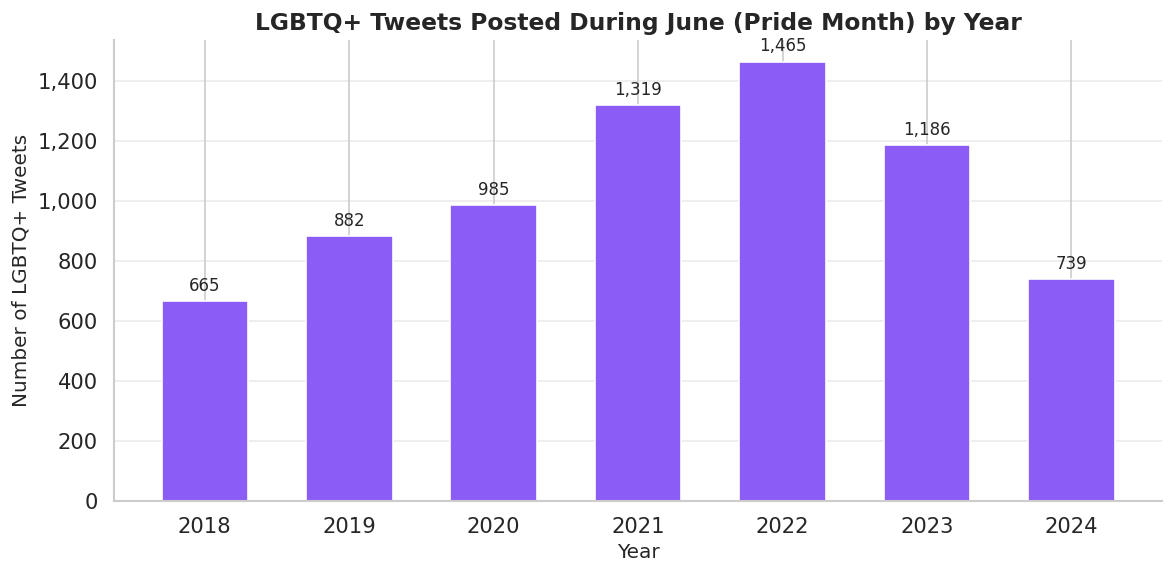

In [39]:
# ── Figure 1: LGBTQ+ tweet count during June by year ─────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    pride_by_year['year'],
    pride_by_year['lgbtq_june_tweets'],
    color=LGBTQ_COLOR, edgecolor='white', width=0.6
)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=10)
ax.set_title('LGBTQ+ Tweets Posted During June (Pride Month) by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Number of LGBTQ+ Tweets')
ax.set_xticks(pride_by_year['year'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(axis='y', alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_pride_june_count_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

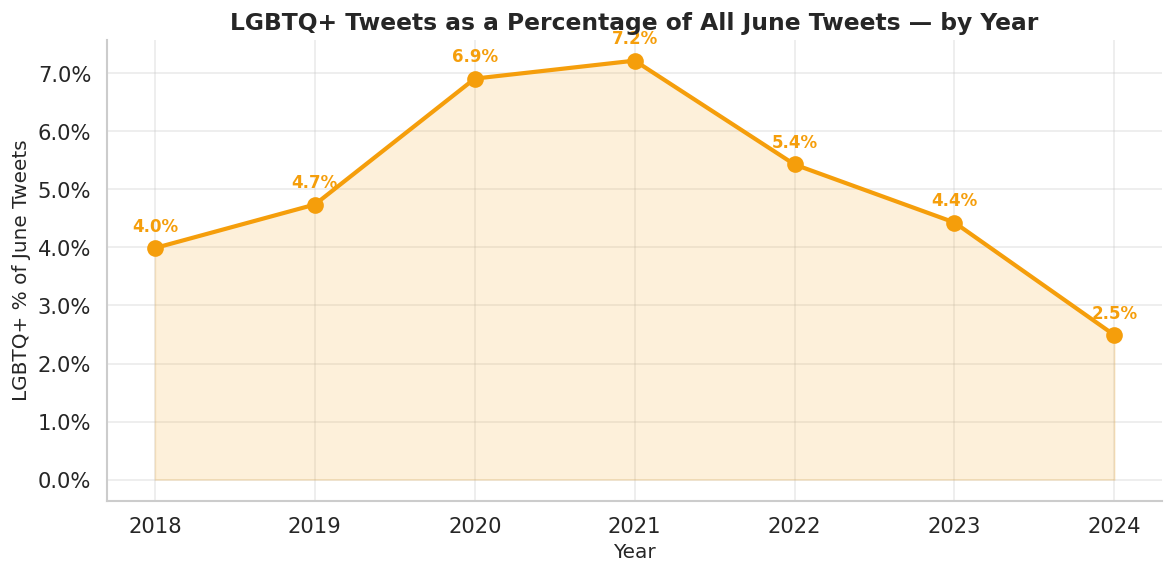

In [40]:
# ── Figure 2: % of June tweets that are LGBTQ+ by year ───────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    pride_by_year['year'],
    pride_by_year['pct_lgbtq_june'],
    marker='o', linewidth=2.5, color=ACCENT_COLOR, markersize=9
)
ax.fill_between(
    pride_by_year['year'],
    pride_by_year['pct_lgbtq_june'],
    alpha=0.15, color=ACCENT_COLOR
)

# Annotate each point with its value
for _, row in pride_by_year.iterrows():
    ax.annotate(
        f"{row['pct_lgbtq_june']:.1f}%",
        xy=(row['year'], row['pct_lgbtq_june']),
        xytext=(0, 10), textcoords='offset points',
        ha='center', fontsize=10, color=ACCENT_COLOR, fontweight='bold'
    )

ax.set_title('LGBTQ+ Tweets as a Percentage of All June Tweets — by Year')
ax.set_xlabel('Year')
ax.set_ylabel('LGBTQ+ % of June Tweets')
ax.set_xticks(pride_by_year['year'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
ax.grid(True, alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_pride_june_pct_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Additional Analysis: LGBTQ+ Tweets as % of All Tweets — Full Year

Section 3.3 already examines June specifically. This section calculates the same metric for the **full calendar year** — what share of a company's total Twitter output was LGBTQ+-related in each year. This gives a broader picture of year-round commitment rather than just Pride Month activity.

LGBTQ+ TWEETS AS % OF ALL TWEETS — BY YEAR (FULL YEAR)


Year,Total Tweets,LGBTQ+ Tweets,LGBTQ+ %
2018,"201,924","6,162",3.05%
2019,"201,834","7,283",3.61%
2020,"195,826","7,437",3.80%
2021,"234,212","9,578",4.09%
2022,"271,079","9,386",3.46%
2023,"301,305","8,990",2.98%
2024,"179,320","3,955",2.21%


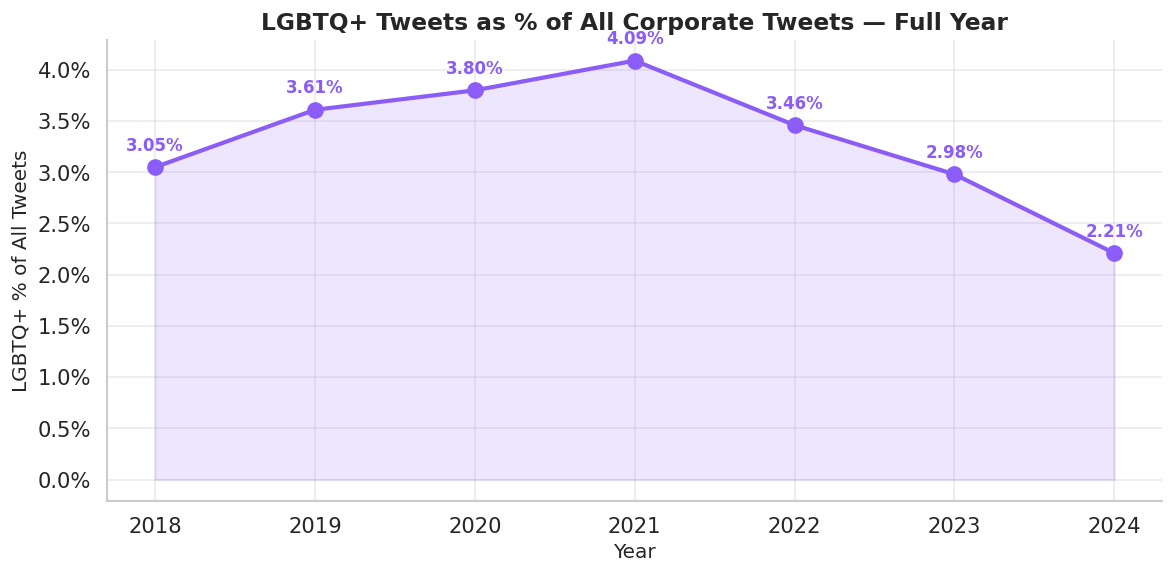

In [44]:
# ── Annual LGBTQ+ % of all tweets ────────────────────────────────────────────
annual_all = (
    df.groupby('year')
    .agg(
        total_tweets = (COL['binary'], 'count'),
        lgbtq_tweets = (COL['binary'], 'sum'),
    )
    .reset_index()
)
annual_all['lgbtq_pct'] = (
    annual_all['lgbtq_tweets'] / annual_all['total_tweets'] * 100
).round(2)

# ── Summary table ────────────────────────────────────────────────────────────
annual_display = annual_all.rename(columns={
    'year'         : 'Year',
    'total_tweets' : 'Total Tweets',
    'lgbtq_tweets' : 'LGBTQ+ Tweets',
    'lgbtq_pct'    : 'LGBTQ+ %',
})
print('LGBTQ+ TWEETS AS % OF ALL TWEETS — BY YEAR (FULL YEAR)')
display(annual_display.style
    .format({'Total Tweets': '{:,}', 'LGBTQ+ Tweets': '{:,}', 'LGBTQ+ %': '{:.2f}%'})
    .background_gradient(subset=['LGBTQ+ %'], cmap='Purples')
    .hide(axis='index'))

# ── Line chart ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    annual_all['year'], annual_all['lgbtq_pct'],
    marker='o', linewidth=2.5, color=LGBTQ_COLOR, markersize=9
)
ax.fill_between(annual_all['year'], annual_all['lgbtq_pct'],
                alpha=0.15, color=LGBTQ_COLOR)

for _, row in annual_all.iterrows():
    ax.annotate(
        f"{row['lgbtq_pct']:.2f}%",
        xy=(row['year'], row['lgbtq_pct']),
        xytext=(0, 10), textcoords='offset points',
        ha='center', fontsize=10, color=LGBTQ_COLOR, fontweight='bold'
    )

ax.set_title('LGBTQ+ Tweets as % of All Corporate Tweets — Full Year')
ax.set_xlabel('Year')
ax.set_ylabel('LGBTQ+ % of All Tweets')
ax.set_xticks(annual_all['year'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
ax.grid(True, alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_annual_lgbtq_pct_fullyear.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Additional Analysis: June vs. Non-June Summary

A quick reference table comparing June against all other months combined for each year. The visualisation for this comparison is included in the Before/During/After section below, which covers the same question with more granularity.

In [45]:
# ── June vs. Non-June LGBTQ+ comparison table ────────────────────────────────
df['_period_jvnj'] = df['month'].apply(lambda m: 'June' if m == 6 else 'Non-June')

jvnj = (
    df.groupby(['year', '_period_jvnj'])
    .agg(
        total_tweets = (COL['binary'], 'count'),
        lgbtq_tweets = (COL['binary'], 'sum'),
    )
    .reset_index()
)
jvnj['lgbtq_pct'] = (jvnj['lgbtq_tweets'] / jvnj['total_tweets'] * 100).round(2)

june_df    = jvnj[jvnj['_period_jvnj'] == 'June'].set_index('year')
nonjune_df = jvnj[jvnj['_period_jvnj'] == 'Non-June'].set_index('year')
years_jvnj = sorted(jvnj['year'].unique())

rows = []
for y in years_jvnj:
    rows.append({
        'Year'                   : y,
        'June LGBTQ+ Tweets'     : int(june_df.loc[y, 'lgbtq_tweets'])    if y in june_df.index    else 0,
        'June LGBTQ+ %'          : june_df.loc[y, 'lgbtq_pct']            if y in june_df.index    else 0,
        'Non-June LGBTQ+ Tweets' : int(nonjune_df.loc[y, 'lgbtq_tweets']) if y in nonjune_df.index else 0,
        'Non-June LGBTQ+ %'      : nonjune_df.loc[y, 'lgbtq_pct']        if y in nonjune_df.index else 0,
    })

jvnj_table = pd.DataFrame(rows)
print('JUNE vs. NON-JUNE LGBTQ+ SUMMARY')
display(jvnj_table.style
    .format({
        'June LGBTQ+ Tweets'     : '{:,}',
        'Non-June LGBTQ+ Tweets' : '{:,}',
        'June LGBTQ+ %'          : '{:.2f}%',
        'Non-June LGBTQ+ %'      : '{:.2f}%',
    })
    .hide(axis='index'))

JUNE vs. NON-JUNE LGBTQ+ SUMMARY


Year,June LGBTQ+ Tweets,June LGBTQ+ %,Non-June LGBTQ+ Tweets,Non-June LGBTQ+ %
2018,665,3.99%,"5,497",2.97%
2019,882,4.74%,"6,401",3.49%
2020,985,6.91%,"6,452",3.55%
2021,"1,319",7.22%,"8,259",3.82%
2022,"1,465",5.43%,"7,921",3.25%
2023,"1,186",4.43%,"7,804",2.84%
2024,739,2.49%,"3,216",2.15%


---
# Additional Analysis: Before, During, and After Pride Month

This section splits each year into three periods to test whether LGBTQ+ communication drops off after Pride Month ends:

- **Jan–May** — Before Pride Month
- **June** — Pride Month
- **Jul–Dec** — After Pride Month

This extends the June vs. Non-June comparison above by separating the non-June period into pre- and post-Pride halves, revealing whether there is any carry-over momentum after June.

In [46]:
# ── Assign before / during / after labels ────────────────────────────────────
def assign_pride_period(month):
    if month < 6:
        return 'Jan–May'
    elif month == 6:
        return 'June'
    else:
        return 'Jul–Dec'

df['pride_period'] = df['month'].apply(assign_pride_period)

PERIOD_ORDER  = ['Jan–May', 'June', 'Jul–Dec']
PERIOD_COLORS = [NON_LGBTQ_COLOR, LGBTQ_COLOR, ACCENT_COLOR]

period_agg = (
    df.groupby(['year', 'pride_period'])
    .agg(
        total_tweets = (COL['binary'], 'count'),
        lgbtq_tweets = (COL['binary'], 'sum'),
    )
    .reset_index()
)
period_agg['lgbtq_pct'] = (
    period_agg['lgbtq_tweets'] / period_agg['total_tweets'] * 100
).round(2)
period_agg['pride_period'] = pd.Categorical(
    period_agg['pride_period'], categories=PERIOD_ORDER, ordered=True
)
period_agg = period_agg.sort_values(['year', 'pride_period'])

# ── Summary table ────────────────────────────────────────────────────────────
period_display = period_agg.rename(columns={
    'year'         : 'Year',
    'pride_period' : 'Period',
    'total_tweets' : 'Total Tweets',
    'lgbtq_tweets' : 'LGBTQ+ Tweets',
    'lgbtq_pct'    : 'LGBTQ+ %',
})
print('LGBTQ+ TWEETS BY PERIOD — JAN–MAY / JUNE / JUL–DEC')
display(period_display.style
    .format({'Total Tweets': '{:,}', 'LGBTQ+ Tweets': '{:,}', 'LGBTQ+ %': '{:.2f}%'})
    .hide(axis='index'))

LGBTQ+ TWEETS BY PERIOD — JAN–MAY / JUNE / JUL–DEC


Year,Period,Total Tweets,LGBTQ+ Tweets,LGBTQ+ %
2018,Jan–May,"87,378","2,550",2.92%
2018,June,"16,675",665,3.99%
2018,Jul–Dec,"97,871","2,947",3.01%
2019,Jan–May,"82,505","3,086",3.74%
2019,June,"18,620",882,4.74%
2019,Jul–Dec,"100,709","3,315",3.29%
2020,Jan–May,"87,920","2,634",3.00%
2020,June,"14,262",985,6.91%
2020,Jul–Dec,"93,644","3,818",4.08%
2021,Jan–May,"90,883","3,947",4.34%


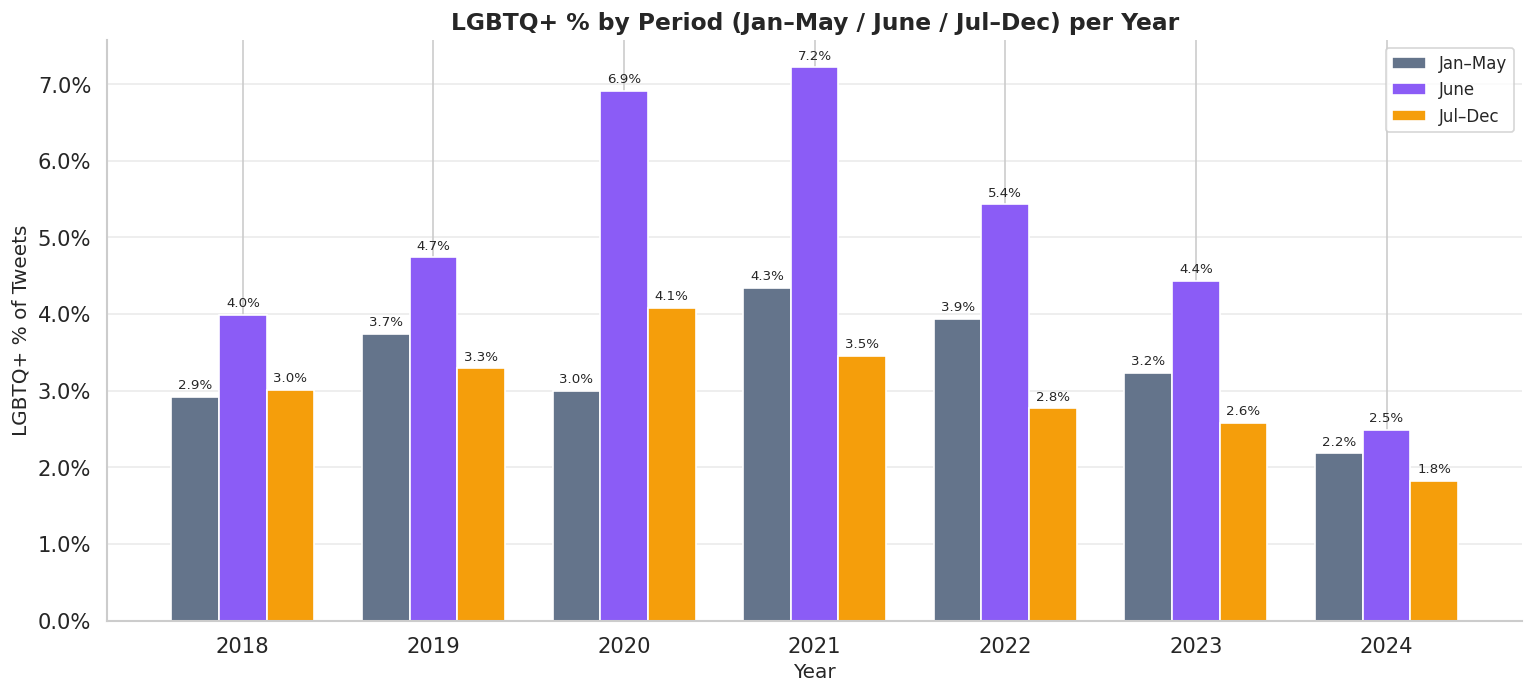

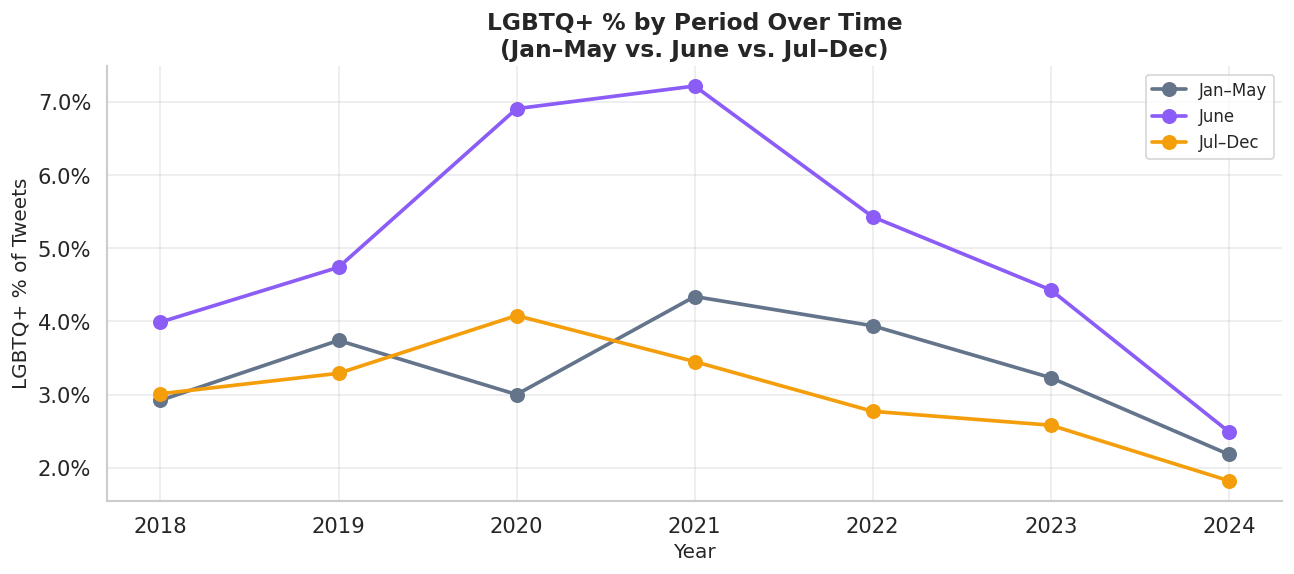

In [47]:
period_pivot_pct = period_agg.pivot(
    index='year', columns='pride_period', values='lgbtq_pct'
)
years_p = period_pivot_pct.index.tolist()
x = np.arange(len(years_p))
w = 0.25

# ── Grouped bar chart: LGBTQ+ % by period per year ───────────────────────────
fig, ax = plt.subplots(figsize=(13, 6))
for i, (period, color) in enumerate(zip(PERIOD_ORDER, PERIOD_COLORS)):
    if period in period_pivot_pct.columns:
        vals = period_pivot_pct[period].values
        bars = ax.bar(x + (i - 1) * w, vals, w,
                      label=period, color=color, edgecolor='white')
        ax.bar_label(bars, labels=[f'{v:.1f}%' for v in vals],
                     padding=3, fontsize=8)

ax.set_title('LGBTQ+ % by Period (Jan–May / June / Jul–Dec) per Year')
ax.set_xlabel('Year')
ax.set_ylabel('LGBTQ+ % of Tweets')
ax.set_xticks(x)
ax.set_xticklabels(years_p)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.1f}%'))
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_bda_grouped_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Line chart: each period's % trend over years ─────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
for period, color in zip(PERIOD_ORDER, PERIOD_COLORS):
    if period in period_pivot_pct.columns:
        ax.plot(
            years_p, period_pivot_pct[period],
            marker='o', linewidth=2.2, color=color,
            label=period, markersize=8
        )

ax.set_title('LGBTQ+ % by Period Over Time\n(Jan–May vs. June vs. Jul–Dec)')
ax.set_xlabel('Year')
ax.set_ylabel('LGBTQ+ % of Tweets')
ax.set_xticks(years_p)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.1f}%'))
ax.legend(fontsize=10)
ax.grid(True, alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_bda_line.png', dpi=150, bbox_inches='tight')
plt.show()



## Saved Figures
The following visualizations were saved to the Colab working directory:
- `fig_lgbtq_pie.png` — Tweet composition pie chart
- `fig_top20_companies.png` — Top companies by total volume
- `fig_top20_lgbtq_companies.png` — Top companies by LGBTQ+ volume
- `fig_engagement_distributions.png` — Engagement metric histograms
- `fig_annual_trends.png` — Year-over-year trend lines
- `fig_monthly_lgbtq.png` — Monthly seasonality charts
- `fig_pride_month_by_year.png` — Pride Month participation by year
- `fig_sentiment_trends.png` — Sentiment by year and month
- `fig_boxplots_engagement.png` — Engagement boxplots by category
- `fig_violin_total_engagement.png` — Total engagement violin plot
- `fig_company_avg_engagement.png` — Company average engagement
- `fig_company_lgbtq_engagement.png` — Company LGBTQ+ engagement
- `fig_scatter_sentiment_engagement.png` — Scatter plots: sentiment vs. engagement
- `fig_top20_orig_posts.png` — Top 20 companies by original post volume
- `fig_top20_orig_lgbtq.png` — Top 20 companies by LGBTQ+ original posts
- `fig_pride_june_count_by_year.png` — LGBTQ+ June tweet count by year
- `fig_pride_june_pct_by_year.png` — LGBTQ+ % of June tweets by year


**Additional Analysis Figures:**

- `fig_annual_lgbtq_pct_fullyear.png` — LGBTQ+ % of all tweets per year (full year)
- `fig_bda_grouped_bar.png` — Jan–May / June / Jul–Dec grouped bar chart
- `fig_bda_line.png` — Jan–May / June / Jul–Dec line trend
